In [20]:
import pandas as pd
import numpy as np
from scipy.io import loadmat
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['PYTHONHASHSEED'] = '0'
os.environ['TF_DETERMINISTIC_OPS'] = '1'
import keras
from keras import layers, Model
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam, RMSprop
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, mean_squared_error
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV
from joblib import dump, load
from scipy.signal import savgol_filter, welch, butter, filtfilt
from scipy.ndimage import gaussian_filter
from numpy import cos, sin
import joblib
from PIL import Image as PILImage
from reportlab.lib.units import cm
from reportlab.platypus import Paragraph, Image, PageBreak, SimpleDocTemplate
from reportlab.lib.styles import getSampleStyleSheet
import gc
from reportlab.lib.pagesizes import A4
import json
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
import textwrap
from scipy.stats import qmc

In [21]:
def set_seed(seed):
    keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()

In [22]:
def def_parametros():
    parametros = [
            "TIME",        "TEMPO_SAD",        "EVENTO",        "HH",        "MM",        "SS",        "MSS",        "TOT",        "ALFAG",        "BETAG",
            "DL",        "DM",        "DN",        "DF",        "NX",        "NY",        "NZ",        "P",        "Q",        "R",        "PB",        "PB1",
            "QB",        "QB1",        "TI",        "T5_C",        "TETAL",        "FIL",        "CID",        "NG",        "PSI",        "PBEX",        "PIX",
            "PIY",        "VB",        "VB1",        "ZPB",        "ZPB1",        "W",        "pa",        "qc",        "Zp",        "Vc",        "Mach",
            "Ta_C",        "Va",        "Alfa",        "Beta",        "Ta_K",        "T",        "No. OBS."
    ]
    return parametros

In [23]:
def butter_lowpass(signal, cutoff_period_s, fs=1.0, order=1):
    cutoff_freq = 1.0 / cutoff_period_s
    nyq = 0.5 * fs
    normal_cutoff = cutoff_freq / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

In [40]:
def parametros_adicionais(df):
    Ta0 = 288.15
    df['theta'] = df['Ta_K']/Ta0

    df['Z'] = 0.3048*df['Zp'] # Altitude em metros
    df['a1'] = df['Z']<=11000
    df['a2'] = df['Z']>11000

    df['pa'] = (1013.25*(1-6.87559e-6*df['Zp'])**(5.25611))*(df['a1'])+(226.306*np.exp(157.696e-6 *(11000-df['Z'])))*(df['a2']) # Pressao em mbar
    df['Rho'] = df['pa']/(2.869*(df['Ta_K'])) # Densidade em kg/m³

    Pa0 = 1013.25
    df['delta'] = df['pa']/Pa0
    
    df['N1_over_sqrt_theta'] = df['NG']/np.sqrt(df['theta'])

    df['Mach2'] = df['Mach']**2

    df['Va2'] = df['Va']**2

    S = 19.3

    df['NX_filtered'] = butter_lowpass(df['NX'], cutoff_period_s=15)
    df['NZ_filtered'] = butter_lowpass(df['NZ'], cutoff_period_s=15)
    df['Alfa_filtered'] = butter_lowpass(df['Alfa'], cutoff_period_s=30)
    df['Va_filtered'] = butter_lowpass(df['Va'], cutoff_period_s=30)
    df['Hdot'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered'])))*df['Va_filtered'] # Hdot em m/s
    df['Hdot_V'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered'])))

    df['Hdot_W_V_dlt'] = (df['NX']*np.cos(np.radians(df['Alfa'])) - df['NZ']*np.sin(np.radians(df['Alfa'])))*df['W']/df['delta'] # (Hdot/V) * (W/delta), em kgf

    df['NZ_W_dlt'] = df['NZ']*df['W']/df['delta']
    df['NZ_W_dlt_sqr'] = df['NZ_W_dlt']**2

    df['NZ_W_dlt_Mach_sqr'] = (df['NZ_W_dlt']/df['Mach'])**2

    # Filtro para cortar dados irrelevantes:
    df = df[df['Va_filtered'] > 90]
    df = df[df['Zp'] > 3000]

    return df

In [25]:
def make_df(tipo_dados):
    if tipo_dados == 'completo':
        files = ['039_2013_VIN_FND', '040_2013_ASO_VTO', '041_2013_GEO_AIR', '042_2013_VAU_FTR']
    else:
        files = ['039_2013_VIN_FND']

    local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados_AT26_VoosCompletos\\'
    parametros = def_parametros()
    all_dfs = []
    for file in files:
        data = loadmat(local + file + '.mat')
        df = pd.DataFrame(data['DADOS'])
        df.columns = parametros
        df['filename'] = file
        all_dfs.append(df)
    df = pd.concat(all_dfs, ignore_index=True)

    df = parametros_adicionais(df)

    df['faixa_altitude'] = None

    if tipo_dados == 'completo':
        df.loc[df['filename'].str.contains('039'), 'faixa_altitude'] = 'A'
        df.loc[df['filename'].str.contains('040'), 'faixa_altitude'] = 'B'
        df.loc[df['filename'].str.contains('041'), 'faixa_altitude'] = 'C'
        df.loc[df['filename'].str.contains('042'), 'faixa_altitude'] = 'D'
    else:
        df.loc[(df['TEMPO_SAD'] > 52400) & (df['TEMPO_SAD'] < 52625), 'faixa_altitude'] = 'A'
        df.loc[(df['TEMPO_SAD'] > 53000) & (df['TEMPO_SAD'] < 53200), 'faixa_altitude'] = 'B'
        df.loc[(df['TEMPO_SAD'] > 53775) & (df['TEMPO_SAD'] < 54073), 'faixa_altitude'] = 'C'
        df.loc[(df['TEMPO_SAD'] > 54750) & (df['TEMPO_SAD'] < 55100), 'faixa_altitude'] = 'D'
        df = df[df['faixa_altitude'].notna()].copy()

    return df

-13.585768869018555
139.93421232910157


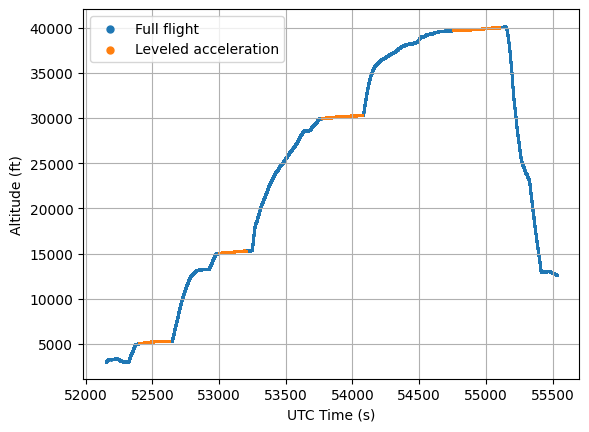

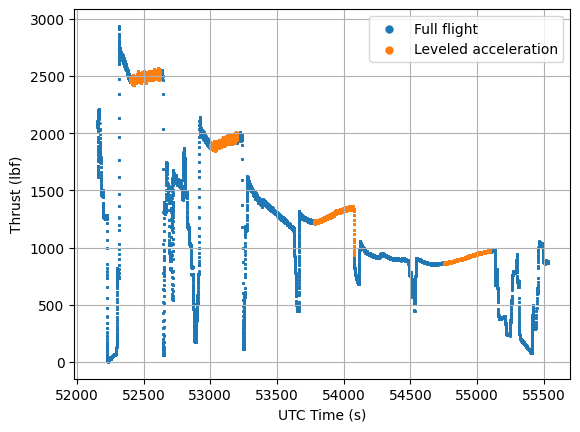

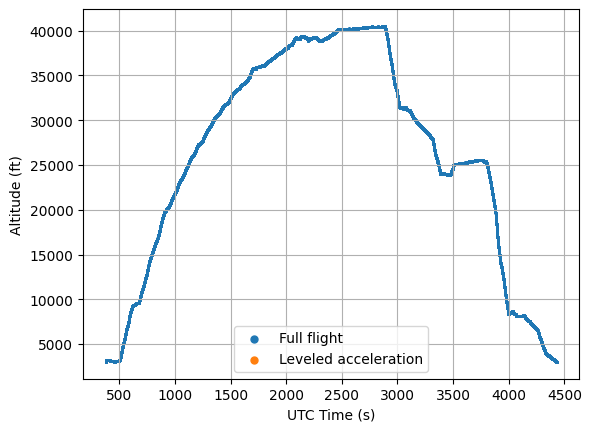

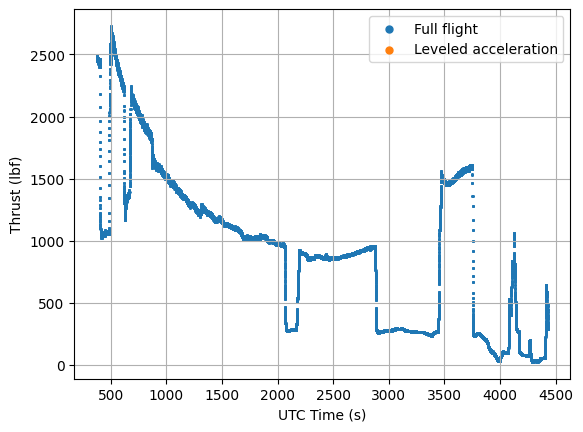

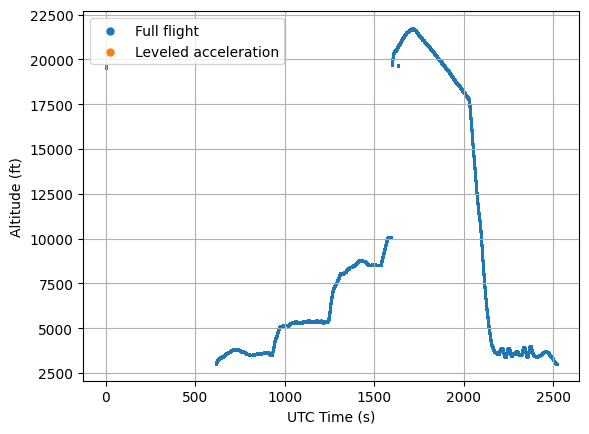

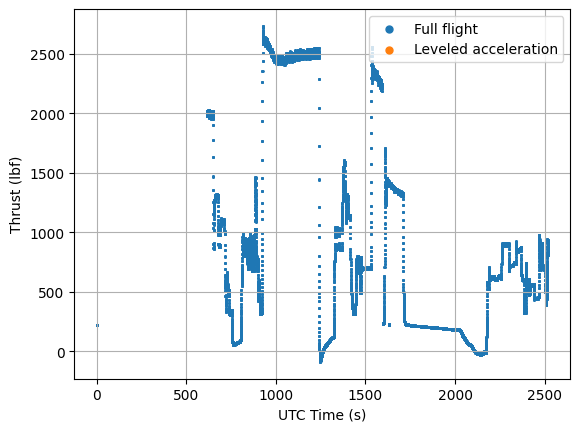

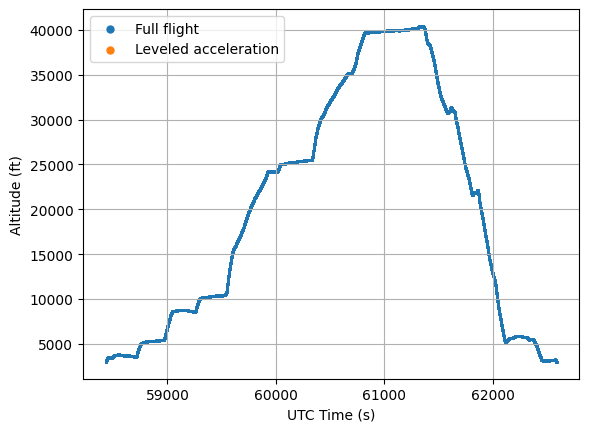

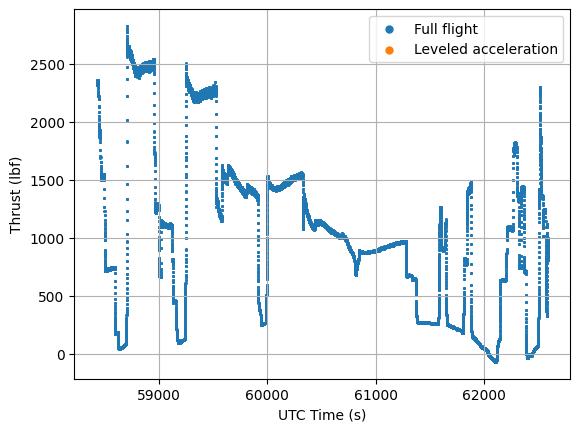

In [26]:
df = make_df('completo')
evaluated_set = 'train'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

# subset = df[df['type'] == evaluated_set]

print(df['Alfa'].min())
print(df['Alfa'].max())

for filename, grupo in df.groupby('filename'):
    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    mask_leveled_acceleration = (
        ((grupo['TEMPO_SAD'] > 52400) & (grupo['TEMPO_SAD'] < 52625)) +
        ((grupo['TEMPO_SAD'] > 53000) & (grupo['TEMPO_SAD'] < 53200)) +
        ((grupo['TEMPO_SAD'] > 53775) & (grupo['TEMPO_SAD'] < 54075)) +
        ((grupo['TEMPO_SAD'] > 54750) & (grupo['TEMPO_SAD'] < 55100))
    )
    grupo_aceleracao_nivelada = grupo[mask_leveled_acceleration]
    grupo = grupo[mask]


    # plt.title('Comparação de Hdot_W_V_dlt Real vs. Predito')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Zp'],      s=dot_size, label='Full flight')
    plt.scatter(grupo_aceleracao_nivelada['TEMPO_SAD'], grupo_aceleracao_nivelada['Zp'],      s=dot_size, label=f'Leveled acceleration')
    plt.xlabel('UTC Time (s)')
    plt.ylabel('Altitude (ft)')
    plt.legend(markerscale=5)
    plt.grid()
    plt.show()

    plt.scatter(grupo['TEMPO_SAD'], grupo['T'],      s=dot_size, label='Full flight')
    plt.scatter(grupo_aceleracao_nivelada['TEMPO_SAD'], grupo_aceleracao_nivelada['T'],      s=dot_size, label=f'Leveled acceleration')
    plt.xlabel('UTC Time (s)')
    plt.ylabel('Thrust (lbf)')
    plt.legend(markerscale=5)
    plt.grid()
    plt.show()

In [27]:
def split_train_test_val(df):
    df['type'] = 'train'    
    df.loc[df['faixa_altitude'] == 'B', 'type'] = 'test'

    test_size = 0.2
    m = round((1-test_size)*len(df.loc[df['type'] == 'test']))
    val_indices = df.loc[df['type'] == 'test'].sample(n=m, random_state=42).index
    df.loc[val_indices, 'type'] = 'val'
    
    return df

In [28]:
def scale_data(df, features1, features2, targets):
    scaler_x1 = MinMaxScaler()
    scaler_x2 = MinMaxScaler()
    scaler_y  = MinMaxScaler()

    cols1 = features1
    cols2 = features2
    colsy = targets

    df[[p+'_scaled' for p in cols1]] = None
    df[[p+'_scaled' for p in cols2]] = None
    df[[p+'_scaled' for p in colsy]] = None

    # for split, method in [('train','fit_transform'), ('test','transform'), ('val','transform')]:
    #     mask = df['type'] == split
    #     df.loc[mask, [p+'_scaled' for p in cols1]] = getattr(scaler_x1, method)(df.loc[mask, cols1])
    #     df.loc[mask, [p+'_scaled' for p in cols2]] = getattr(scaler_x2, method)(df.loc[mask, cols2])
    #     # df.loc[mask, [p+'_scaled' for p in colsy]] = getattr(scaler_y,  method)(df.loc[mask, colsy])
    #     df.loc[mask, [p+'_scaled' for p in colsy]] = df.loc[mask, colsy].values  # sem escalonamento
    for split, method in [('train','fit_transform'), ('test','transform'), ('val','transform')]:
        mask = df['type'] == split
        df.loc[mask, [p+'_scaled' for p in cols1]] = getattr(scaler_x1, method)(df.loc[mask, cols1])
        df.loc[mask, [p+'_scaled' for p in cols2]] = getattr(scaler_x2, method)(df.loc[mask, cols2])
        df.loc[mask, [p+'_scaled' for p in colsy]] = getattr(scaler_y,  method)(df.loc[mask, colsy])

    return df, scaler_x1, scaler_x2, scaler_y

In [29]:
import tensorflow as tf

class PMGModel(keras.Model):
    _TRACKERS = ('mono_penalty_ng', 'mono_penalty_t', 'anchor_penalty', 'total_loss')

    def __init__(self, main_model, z1_model, ng_index,
                 lambda_mono_ng=1.0, lambda_mono_t=0.0, lambda_anchor=0.0, **kwargs):
        super().__init__(**kwargs)
        self.main_model = main_model
        self.z1_model = z1_model
        self.ng_index = ng_index
        self.lambda_mono_ng = lambda_mono_ng
        self.lambda_mono_t = lambda_mono_t
        self.lambda_anchor = lambda_anchor
        self.penalty_ng_tracker = keras.metrics.Mean(name='mono_penalty_ng')
        self.penalty_t_tracker = keras.metrics.Mean(name='mono_penalty_t')
        self.anchor_tracker = keras.metrics.Mean(name='anchor_penalty')
        self.total_loss_tracker = keras.metrics.Mean(name='total_loss')

    def call(self, inputs, training=False):
        return self.main_model(inputs, training=training)

    @property
    def metrics(self):
        return super().metrics + [self.penalty_ng_tracker, self.penalty_t_tracker,
                                  self.anchor_tracker, self.total_loss_tracker]

    def _physics_terms(self, x1, dx1dt, t_mask, training):
        """Um único forward pass de NN1 e um único gradiente dZ1/dX1, reaproveitados em:
        (i) dZ1/dNG >= 0, (ii) dZ1/dt = grad(Z1)·dX1/dt >= 0, (iii) ancoragem."""
        zero = tf.constant(0.0)
        usa_ng = self.ng_index is not None and self.lambda_mono_ng != 0
        usa_t = self.lambda_mono_t != 0
        if not (usa_ng or usa_t or self.lambda_anchor != 0):
            return zero, zero, None

        with tf.GradientTape() as tape_phys:
            tape_phys.watch(x1)
            z1 = self.z1_model(x1, training=training)

        if not (usa_ng or usa_t):
            return zero, zero, z1

        dz1_dx1 = tape_phys.gradient(z1, x1)            # (batch, n_features1)

        if usa_ng:
            pen_ng = tf.reduce_mean(tf.nn.relu(-dz1_dx1[:, self.ng_index]))
        else:
            pen_ng = zero

        if usa_t:
            dz1_dt = tf.reduce_sum(dz1_dx1 * dx1dt, axis=1)   # regra da cadeia
            pen_t = tf.reduce_sum(tf.nn.relu(-dz1_dt) * t_mask) / (tf.reduce_sum(t_mask) + 1e-8)
        else:
            pen_t = zero

        return pen_ng, pen_t, z1

    def _anchor_penalty(self, z1, anchor_target, anchor_mask):
        if self.lambda_anchor == 0 or z1 is None:
            return tf.constant(0.0)
        erro2 = tf.square(z1[:, 0] - anchor_target) * anchor_mask
        return tf.reduce_sum(erro2) / (tf.reduce_sum(anchor_mask) + 1e-8)

    def _total(self, data_loss, pen_ng, pen_t, pen_anchor):
        return (data_loss
                + self.lambda_mono_ng * pen_ng
                + self.lambda_mono_t * pen_t
                + self.lambda_anchor * pen_anchor)

    def _update_metrics(self, y, y_pred, data_loss, pen_ng, pen_t, pen_anchor, total_loss):
        self.penalty_ng_tracker.update_state(pen_ng)
        self.penalty_t_tracker.update_state(pen_t)
        self.anchor_tracker.update_state(pen_anchor)
        self.total_loss_tracker.update_state(total_loss)
        for metric in self.metrics:
            if metric.name == 'loss':
                metric.update_state(data_loss)
            elif metric.name not in self._TRACKERS:
                metric.update_state(y, y_pred)
        return {m.name: m.result() for m in self.metrics}

    def train_step(self, data):
        x, y = data
        x1, x2, anchor_target, anchor_mask, dx1dt, t_mask = x
        with tf.GradientTape() as tape:
            pen_ng, pen_t, z1 = self._physics_terms(x1, dx1dt, t_mask, training=True)
            pen_anchor = self._anchor_penalty(z1, anchor_target, anchor_mask)
            y_pred = self.main_model([x1, x2], training=True)
            data_loss = self.compute_loss(x=x, y=y, y_pred=y_pred)
            total_loss = self._total(data_loss, pen_ng, pen_t, pen_anchor)

        gradients = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))
        return self._update_metrics(y, y_pred, data_loss, pen_ng, pen_t, pen_anchor, total_loss)

    def test_step(self, data):
        x, y = data
        x1, x2, anchor_target, anchor_mask, dx1dt, t_mask = x
        y_pred = self.main_model([x1, x2], training=False)
        data_loss = self.compute_loss(x=x, y=y, y_pred=y_pred)
        pen_ng, pen_t, z1 = self._physics_terms(x1, dx1dt, t_mask, training=False)
        pen_anchor = self._anchor_penalty(z1, anchor_target, anchor_mask)
        total_loss = self._total(data_loss, pen_ng, pen_t, pen_anchor)
        return self._update_metrics(y, y_pred, data_loss, pen_ng, pen_t, pen_anchor, total_loss)

In [30]:
def build_model(features1, features2, architecture={}, hyperparameters={}):
    # Valores genéricos: valem para as duas sub-redes quando não há valor específico
    neurons_default  = architecture.get('neurons', 32)
    n_hidden_default = architecture.get('camadas_ocultas', 2)

    # Valores específicos de cada sub-rede (Z1 -> NN1, Z2 -> NN2)
    neurons_z1   = architecture.get('neurons_z1', neurons_default)
    n_hidden_z1  = architecture.get('camadas_ocultas_z1', n_hidden_default)
    neurons_z2   = architecture.get('neurons_z2', neurons_default)
    n_hidden_z2  = architecture.get('camadas_ocultas_z2', n_hidden_default)

    activation       = architecture.get('activation', 'relu')
    dropout_rate     = architecture.get('dropout', 0.0)

    optimizer_name   = hyperparameters.get('optimizer', 'adam')
    learning_rate    = hyperparameters.get('learning_rate', 0.001)
    epochs           = hyperparameters.get('epochs', 100)
    batch_size       = hyperparameters.get('batch_size', 32)
    patience         = hyperparameters.get('patience', 3)

    def build_subnetwork(input_tensor, name_prefix, neurons, n_hidden):
        x = input_tensor
        for i in range(n_hidden):
            x = layers.Dense(
                neurons,
                activation=activation,
                name=f'{name_prefix}_hidden_{i+1}'
            )(x)
            if dropout_rate > 0:
                x = layers.Dropout(dropout_rate, name=f'{name_prefix}_dropout_{i+1}')(x)
        z = layers.Dense(1, activation='softplus', name=f'{name_prefix}_output')(x)
        return z

    input_x1 = layers.Input(shape=(len(features1),), name='Entrada_X1')
    input_x2 = layers.Input(shape=(len(features2),), name='Entrada_X2')

    z1 = build_subnetwork(input_x1, 'NN1', neurons_z1, n_hidden_z1)
    z2 = build_subnetwork(input_x2, 'NN2', neurons_z2, n_hidden_z2)

    output = layers.Subtract(name='Saida_Y')([z1, z2])

    functional_model = Model(inputs=[input_x1, input_x2], outputs=output)
    z1_model = Model(inputs=input_x1, outputs=z1, name='Z1_extractor')

    mono_feature   = hyperparameters.get('mono_feature', 'N1_over_sqrt_theta')
    ng_index       = features1.index(mono_feature) if mono_feature in features1 else None
    # 'lambda_mono' antigo continua aceito como fallback para a restrição em NG
    lambda_mono_ng = hyperparameters.get('lambda_mono_ng', hyperparameters.get('lambda_mono', 1.0))
    lambda_mono_t  = hyperparameters.get('lambda_mono_t', 0.0)
    lambda_anchor  = hyperparameters.get('lambda_anchor', 0.0)

    model = PMGModel(
        main_model=functional_model,
        z1_model=z1_model,
        ng_index=ng_index,
        lambda_mono_ng=lambda_mono_ng,
        lambda_mono_t=lambda_mono_t,
        lambda_anchor=lambda_anchor,
    )

    optimizer = keras.optimizers.get({
        'class_name': optimizer_name,
        'config': {'learning_rate': learning_rate}
    })

    model.compile(optimizer=optimizer, loss='mse')

    model.epochs     = epochs
    model.batch_size = batch_size
    model.patience   = patience

    return model

In [31]:
def calcular_dx1dt_scaled(df, features1_scaled, cutoff_period_s=10.0, gap_factor=5.0, min_seg_len=20):
    """d(X1_scaled)/d(TEMPO_SAD), por voo e por trecho contínuo (os filtros Va>90 e
    Zp>3000 abrem buracos na série). Passa-baixa + diferenças centrais.
    Retorna (dx1dt [N, n_feat], valido [N]) na mesma ordem de df."""
    dx1dt = np.zeros((len(df), len(features1_scaled)), dtype=np.float32)
    valido = np.zeros(len(df), dtype=np.float32)
    pos = pd.Series(np.arange(len(df)), index=df.index)

    for _, grupo in df.groupby('filename'):
        grupo = grupo.sort_values('TEMPO_SAD')
        t = grupo['TEMPO_SAD'].to_numpy(dtype=float)
        dt = np.diff(t)
        dt_med = np.median(dt[dt > 0])
        fs = 1.0 / dt_med
        quebras = np.where((dt <= 0) | (dt > gap_factor * dt_med))[0] + 1

        for seg in np.split(np.arange(len(grupo)), quebras):
            if len(seg) < min_seg_len:
                continue          # trecho curto demais: fica fora da penalidade (valido = 0)
            idx = pos[grupo.index[seg]].to_numpy()
            for j, col in enumerate(features1_scaled):
                x = grupo[col].to_numpy(dtype=float)[seg]
                x_f = butter_lowpass(x, cutoff_period_s=cutoff_period_s, fs=fs)
                dx1dt[idx, j] = np.gradient(x_f, t[seg])
            valido[idx] = 1.0

    return dx1dt, valido

def _anchor_mask_por_condicao(df, anchor_points, tol_mach=0.01, tol_n1=1.0,
                              col_mach='Mach', col_n1='N1_over_sqrt_theta'):
    """Marca como âncora os pontos com |Mach - M0| <= tol_mach e |N1/sqrt(theta) - N0| <= tol_n1,
    para cada (M0, N0) em anchor_points. Usa as colunas físicas (não escalonadas)."""
    mach = df[col_mach].to_numpy(dtype=float)
    n1 = df[col_n1].to_numpy(dtype=float)
    mask = np.zeros(len(df), dtype=bool)
    for m0, n0 in anchor_points:
        mask |= (np.abs(mach - m0) <= tol_mach) & (np.abs(n1 - n0) <= tol_n1)
    return mask.astype(np.float32)

def calcular_offset_ancoras(df, hyperparameters, estatistica='media'):
    """Deslocamento global c tal que Z1 + c ajusta Tn_dlt nas âncoras do treino.
    Retorna (c, desvio-padrão do resíduo nas âncoras, n_ancoras).
    Exige linhas de treino em df."""
    anchor_points = hyperparameters.get('anchor_points')
    if anchor_points is None:
        print("AVISO: sem 'anchor_points'; offset não calculado (c = 0).")
        df['ancora'] = False
        return 0.0, float('nan'), 0

    df['ancora'] = _anchor_mask_por_condicao(
        df, anchor_points,
        tol_mach=hyperparameters.get('anchor_tol_mach', 0.01),
        tol_n1=hyperparameters.get('anchor_tol_n1', 1.0),
    ).astype(bool)

    sel = df['ancora'] & (df['type'] == 'train')
    residuo = df.loc[sel, 'Tn_dlt'] - df.loc[sel, 'Z1']
    if residuo.empty:
        print("AVISO: nenhuma âncora no treino; offset não calculado (c = 0).")
        return 0.0, float('nan'), 0

    c = residuo.median() if estatistica == 'mediana' else residuo.mean()
    return float(c), float(residuo.std()), int(sel.sum())

def train_model(df, features1, features2, targets, model, hyperparameters, scaler_y):

    features1_scaled = [item + '_scaled' for item in features1]
    features2_scaled = [item + '_scaled' for item in features2]
    targets_scaled = [item + '_scaled' for item in targets]

    train_mask = df['type'] == 'train'
    val_mask = df['type'] == 'val'

    X1_train, X1_val = np.array(df.loc[train_mask, features1_scaled]).astype(np.float32), np.array(df.loc[val_mask, features1_scaled]).astype(np.float32)
    X2_train, X2_val = np.array(df.loc[train_mask, features2_scaled]).astype(np.float32), np.array(df.loc[val_mask, features2_scaled]).astype(np.float32)
    Y_train, Y_val = np.array(df.loc[train_mask, targets_scaled]).astype(np.float32), np.array(df.loc[val_mask, targets_scaled]).astype(np.float32)

        # --- Ancoragem de Z1 em Tn_dlt ---
    anchor_feature = hyperparameters.get('anchor_feature', 'Tn_dlt')

    if anchor_feature not in df.columns:
        df['Tn_dlt'] = (df['T'] * np.cos(np.radians(df['Alfa'])) / df['delta']) * 0.453592

    anchor_scaled_full = scaler_y.transform(df[[anchor_feature]].values)[:, 0].astype(np.float32)
    anchor_target_train = anchor_scaled_full[train_mask.values]
    anchor_target_val = anchor_scaled_full[val_mask.values]

    anchor_points = hyperparameters.get('anchor_points')   # ex.: [(0.5, 100.0)] ou None

    if anchor_points is not None:
        # Seleção por condição de voo: Mach = M0 ± tol e N1/sqrt(theta) = N0 ± tol
        anchor_mask_full = _anchor_mask_por_condicao(
            df, anchor_points,
            tol_mach=hyperparameters.get('anchor_tol_mach', 0.01),
            tol_n1=hyperparameters.get('anchor_tol_n1', 1.0),
        )
        anchor_mask_train = anchor_mask_full[train_mask.values]
        anchor_mask_val = anchor_mask_full[val_mask.values]
        n_anc = int(anchor_mask_train.sum())
        print(f"Âncoras (treino): {n_anc} pontos ({100 * n_anc / len(anchor_mask_train):.2f}%)")
        if n_anc == 0:
            print("AVISO: nenhum ponto de treino satisfaz as condições de ancoragem.")
    else:
        # Comportamento antigo: fração aleatória (mantido para reproduzir rodadas anteriores)
        anchor_fraction = hyperparameters.get('anchor_fraction', 0.01)

        def _build_anchor_mask(mask_split, fraction, seed):
            n = int(mask_split.sum())
            mask_arr = np.zeros(n, dtype=np.float32)
            n_ativos = max(1, int(round(fraction * n))) if fraction > 0 else 0
            if n_ativos > 0:
                rng = np.random.RandomState(seed)
                idx_ativos = rng.choice(n, size=n_ativos, replace=False)
                mask_arr[idx_ativos] = 1.0
            return mask_arr

        anchor_mask_train = _build_anchor_mask(train_mask, anchor_fraction, seed=hyperparameters.get('seed', 0))
        anchor_mask_val = _build_anchor_mask(val_mask, anchor_fraction, seed=hyperparameters.get('seed', 1))
    
    # --- Monotonicidade temporal: dZ1/dt = grad(Z1) · dX1/dt >= 0 ---
    if hyperparameters.get('lambda_mono_t', 0.0) != 0:
        dx1dt_all, t_mask_all = calcular_dx1dt_scaled(
            df, features1_scaled,
            cutoff_period_s=hyperparameters.get('dt_cutoff_period_s', 10.0)
        )
        # Normaliza a magnitude de dX1/dt (sinal preservado) para lambda_mono_t
        # ficar numa ordem de grandeza comparável à de lambda_mono_ng
        ref = train_mask.values & (t_mask_all > 0)
        escala = np.mean(np.linalg.norm(dx1dt_all[ref], axis=1))
        dx1dt_all = (dx1dt_all / (escala + 1e-12)).astype(np.float32)

        # Opcional: restringir a penalidade a uma região (coluna booleana do df)
        col_regiao = hyperparameters.get('mono_t_region_col')
        if col_regiao is not None:
            t_mask_all = t_mask_all * df[col_regiao].to_numpy(dtype=np.float32)
    else:
        dx1dt_all = np.zeros((len(df), len(features1_scaled)), dtype=np.float32)
        t_mask_all = np.zeros(len(df), dtype=np.float32)

    dx1dt_train, dx1dt_val = dx1dt_all[train_mask.values], dx1dt_all[val_mask.values]
    t_mask_train, t_mask_val = t_mask_all[train_mask.values], t_mask_all[val_mask.values]

    callback = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=hyperparameters['patience'],
        restore_best_weights=True
    )

    print("Treinando modelo...")
    training_history = model.fit(
        [X1_train, X2_train, anchor_target_train, anchor_mask_train, dx1dt_train, t_mask_train], Y_train,
        epochs=hyperparameters['epochs'],
        batch_size=hyperparameters['batch_size'],
        callbacks=[callback],
        validation_data=([X1_val, X2_val, anchor_target_val, anchor_mask_val, dx1dt_val, t_mask_val], Y_val),
        verbose=0
    )

    joblib.dump(training_history.history, './trainHistoryDict.pkl')

    trained_model = model.main_model if isinstance(model, PMGModel) else model
    trained_model.save('./model.keras')

    return trained_model, training_history

In [32]:
def pipeline(tipo_dados, architecture, hyperparameters, features1, features2, targets, mode, seed=0):
    set_seed(seed)
    df = make_df(tipo_dados)
    df = split_train_test_val(df)
    df, scaler_x1, scaler_x2, scaler_y = scale_data(df, features1, features2, targets)

    if mode == 'train':
        model = build_model(features1, features2, architecture, hyperparameters)
        model, training_history = train_model(df, features1, features2, targets, model, hyperparameters, scaler_y)  # <-- scaler_y adicionado
    elif mode == 'read':
        print('Carregando o modelo...')
        model, training_history = keras.models.load_model('./model.keras'), joblib.load('./trainHistoryDict.pkl')
    return df, scaler_x1, scaler_x2, scaler_y, model, training_history

In [33]:
def evaluate(model, df, features1, features2, targets, scaler_y, evaluated_set='test'):

    features1_scaled = [item + '_scaled' for item in features1]
    features2_scaled = [item + '_scaled' for item in features2]

    # Previsão sobre todo o dataframe
    X_all = [
        np.array(df[features1_scaled]).astype(np.float32),
        np.array(df[features2_scaled]).astype(np.float32)
    ]

    pred_scaled_all = model.predict(X_all)
    pred_all = scaler_y.inverse_transform(pred_scaled_all)
    # pred_all = pred_scaled_all

    for i, item in enumerate(targets):
        df[item + '_pred'] = pred_all[:, i]

    # Monta results somente com o subconjunto avaliado
    mask = df['type'] == evaluated_set

    pred = pred_all[mask.values]
    real = np.array(df.loc[mask, targets]).astype(np.float32)

    erro = abs(pred - real)
    avg_error = np.nanmean(erro, axis=0).astype(np.float32)


    results = {
        'predicted': pred,
        'real': real,
        'rel_error': erro,
        'avg_error': avg_error
    }

    return results, df

In [34]:
def analyze (
        tipo_dados,
        features1,
        features2,
        targets,
        architecture={
            'neurons_z1': 32,
            'camadas_ocultas_z1': 3,
            'neurons_z2': 32,
            'camadas_ocultas_z2': 3,
            'activation': 'relu',
            'dropout': 0.0
        },
        hyperparameters={
            'optimizer': 'adam',
            'learning_rate': 1e-3,
            'epochs': 200,
            'batch_size': 64,
            'patience': 20,
            'lambda_mono_ng': 1.0,   # penalidade dZ1/dNG < 0
            'lambda_mono_t':  0.0,   # penalidade dZ1/dt  < 0 (regra da cadeia via dX1/dt)    
        },
        evaluated_set='test',
        mode='train',
        seed=0,
        plot=False
        ):
    df, scaler_x1, scaler_x2, scaler_y, model, training_history = pipeline(
        tipo_dados=tipo_dados,
        architecture=architecture,
        hyperparameters=hyperparameters,
        features1=features1,
        features2=features2,
        targets=targets,
        mode=mode,
        seed=seed
    )

    targets_names = targets[0]
    for i in range(1, len(targets)):
        targets_names += '_' + targets[i]

    results, df = evaluate(model, df, features1, features2, targets, scaler_y, evaluated_set)

    if plot:
        plt.plot(training_history.history['loss'])
        plt.plot(training_history.history['val_loss'])
        plt.title('Model Loss')
        plt.ylabel('Loss')
        plt.xlabel('Epoch')
        plt.legend(['Train', 'Validation'], loc='upper left')
        plt.grid()
        plt.savefig(f'{targets_names}_approach_training.png')
        plt.show()

        _, axs = plt.subplots(
            2 * len(targets),
            1,
            sharex=True,
            # figsize=(12, 3 * len(targets)),
            constrained_layout=True
        )
        axs = axs.flatten()
        dot_size = 2

        for i, item in enumerate(targets):
            axs[2*i].set_title(f'Comparação de {item} Real vs. Predito')
            axs[2*i].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], df.loc[df['type']==evaluated_set][f'{item}'], dot_size, label=f'Ground Truth {item}')
            axs[2*i].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], df.loc[df['type']==evaluated_set][f'{item}_pred'], dot_size, label=f'Estimated {item}')
            axs[2*i].legend()
            axs[2*i].grid()

            axs[2*i+1].set_title(f'Erro médio (|pred-real|): {results["avg_error"][i]:.2f}')
            axs[2*i+1].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], results["rel_error"][:,i], dot_size)
            axs[2*i+1].legend()
            axs[2*i+1].grid()

        plt.savefig(f'figures/{targets_names}_approach_results.png')
        plt.show()

    return df, scaler_x1, scaler_x2, scaler_y, model, training_history, results

In [35]:
def mase_pointwise(y_pred, y_true):
    """
    Erro ponto a ponto normalizado pelo naive forecast (passo anterior de y_true).
    Retorna array com mesma forma de y_true.
    """
    naive_mae = np.mean(np.abs(np.diff(y_true)))  # denominador escalar
    if naive_mae == 0:
        return np.full(len(y_true), np.nan)
    return np.abs(y_pred - y_true) / naive_mae

[]

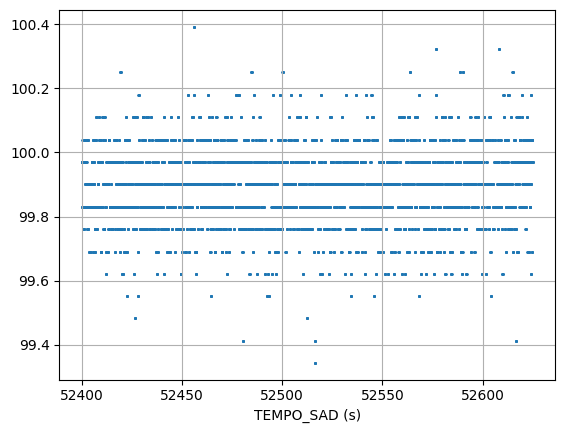

In [95]:
df_cal = make_df('')
# mask = (df_cal['faixa_altitude'] == 'D')
# df_cal = df_cal[mask].copy()
# plt.scatter(df_cal[df_cal['faixa_altitude'] == 'A']['TEMPO_SAD'], df_cal[df_cal['faixa_altitude'] == 'A']['T'], s=1, label='T_A')
# plt.scatter(df_cal[df_cal['faixa_altitude'] == 'B']['TEMPO_SAD'], df_cal[df_cal['faixa_altitude'] == 'B']['T'], s=1, label='T_B')
# plt.scatter(df_cal[df_cal['faixa_altitude'] == 'C']['TEMPO_SAD'], df_cal[df_cal['faixa_altitude'] == 'C']['T'], s=1, label='T_C')
# plt.scatter(df_cal[df_cal['faixa_altitude'] == 'D']['TEMPO_SAD'], df_cal[df_cal['faixa_altitude'] == 'D']['T'], s=1, label='T_D')
plt.scatter(df_cal[df_cal['faixa_altitude'] == 'A']['TEMPO_SAD'], df_cal[df_cal['faixa_altitude'] == 'A']['NG'], s=1, label='NG_A')
# plt.scatter(df_cal[df_cal['faixa_altitude'] == 'B']['TEMPO_SAD'], df_cal[df_cal['faixa_altitude'] == 'B']['NG'], s=1, label='NG_B')
# plt.scatter(df_cal[df_cal['faixa_altitude'] == 'C']['TEMPO_SAD'], df_cal[df_cal['faixa_altitude'] == 'C']['NG'], s=1, label='NG_C')
# plt.scatter(df_cal[df_cal['faixa_altitude'] == 'D']['TEMPO_SAD'], df_cal[df_cal['faixa_altitude'] == 'D']['NG'], s=1, label='NG_D')
# plt.legend()
plt.xlabel('TEMPO_SAD (s)')
plt.grid()
plt.plot()

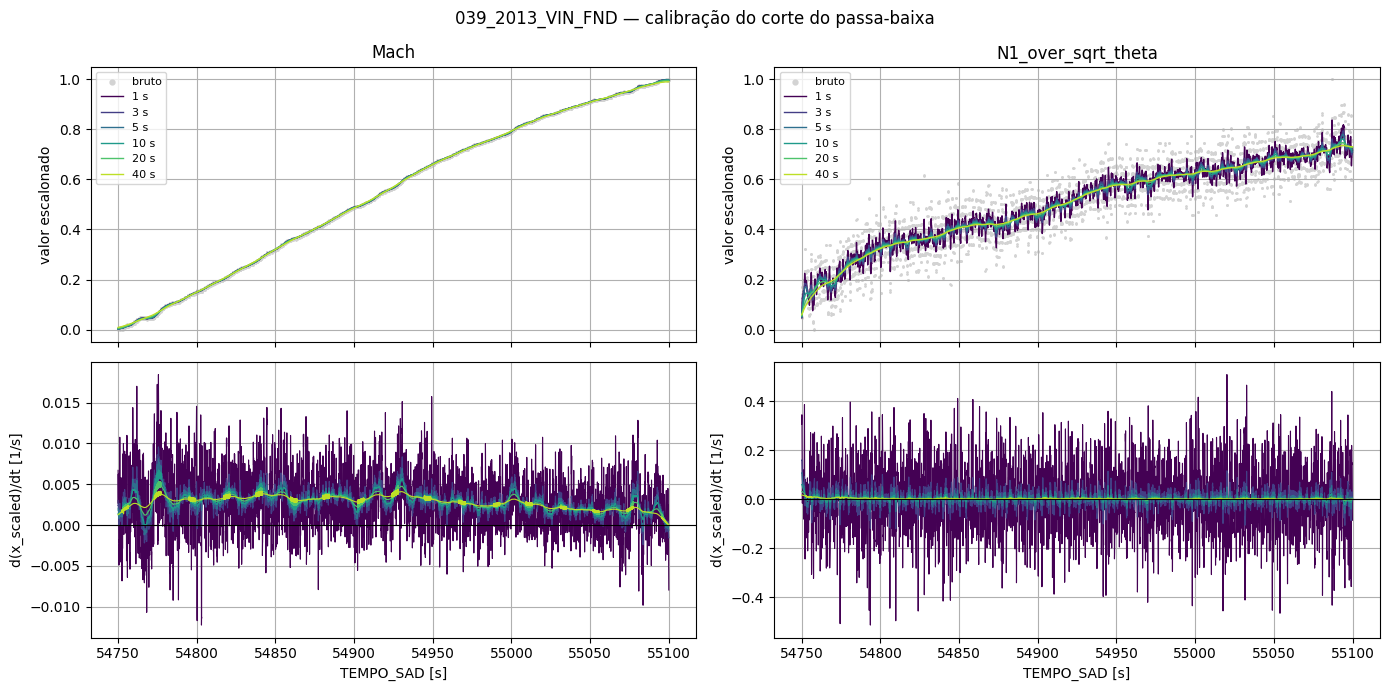

atenuacao_pico  frac_negativa  \
feature            cutoff_s                                  
Mach               1                  0.000          0.198   
                   3                  0.434          0.022   
                   5                  0.464          0.014   
                   10                 0.517          0.002   
                   20                 0.591          0.000   
                   40                 0.646          0.000   
N1_over_sqrt_theta 1                  0.000          0.495   
                   3                  0.751          0.484   
                   5                  0.871          0.460   
                   10                 0.946          0.389   
                   20                 0.970          0.254   
                   40                 0.971          0.068   

                             trocas_sinal_por_min  
feature            cutoff_s                        
Mach               1                      167.128  
                   3                        8.742  
                   5                        2.228  
                   10                       1.543  
                   20                       0.171  
                   40                       0.000  
N1_over_sqrt_theta 1                      199.696  
                   3                      119.475  
                   5                       94.106  
                   10                      64.966  
                   20                      30.340  
                   40                       8.742

In [61]:
# ============ Calibração de dt_cutoff_period_s ============
CUTOFFS    = [1, 3, 5, 10, 20, 40]            # períodos de corte a comparar [s]
# CUTOFFS    = [20, 40]            # períodos de corte a comparar [s]
FEATURES1  = ['Mach', 'N1_over_sqrt_theta']
FEATURES2  = ['Mach2', 'NZ_W_dlt']
TARGETS    = ['Hdot_W_V_dlt']
ZOOM       = None      # ex.: {'039_2013_VIN_FND': (53700, 54150)} para ampliar um trecho; None = voo todo

df_cal = make_df('')
t0, t = (5e4, 7e4)
# mask = (df_cal['TEMPO_SAD'] > t0) & (df_cal['TEMPO_SAD'] < t)
# mask = (df_cal['faixa_altitude'] == 'A') | (df_cal['faixa_altitude'] == 'B') | (df_cal['faixa_altitude'] == 'C') | (df_cal['faixa_altitude'] == 'D')
mask = (df_cal['faixa_altitude'] == 'D')
df_cal = df_cal[mask].copy()
# df_cal = split_train_test_val(df_cal)
# df_cal, _, _, _ = scale_data(df_cal, FEATURES1, FEATURES2, TARGETS)

f1s = [f + '_scaled' for f in FEATURES1]
df_cal[f1s] = MinMaxScaler().fit_transform(df_cal[FEATURES1]).astype(float)

# f1s = [f + '_scaled' for f in FEATURES1]
# df_cal[f1s] = df_cal[f1s].astype(float)

# Derivadas para cada corte (sem a normalização de magnitude do train_model)
derivs = {}
for c in CUTOFFS:
    dx, valido = calcular_dx1dt_scaled(df_cal, f1s, cutoff_period_s=c)
    derivs[c] = dx
valido = valido.astype(bool)

# Sinais filtrados (só para visualização), com a mesma segmentação da função
def _filtrado(grupo, col, c, gap_factor=5.0, min_seg_len=20):
    t = grupo['TEMPO_SAD'].to_numpy(float)
    x = grupo[col].to_numpy(float)
    out = np.full(len(x), np.nan)
    dt = np.diff(t); dt_med = np.median(dt[dt > 0])
    quebras = np.where((dt <= 0) | (dt > gap_factor * dt_med))[0] + 1
    for seg in np.split(np.arange(len(x)), quebras):
        if len(seg) >= min_seg_len:
            out[seg] = butter_lowpass(x[seg], cutoff_period_s=c, fs=1.0 / dt_med)
    return out

pos = pd.Series(np.arange(len(df_cal)), index=df_cal.index)
cores = plt.cm.viridis(np.linspace(0, 0.9, len(CUTOFFS)))
linhas_tabela = []

for filename, grupo in df_cal.groupby('filename'):
    grupo = grupo.sort_values('TEMPO_SAD')
    if ZOOM is not None:
        if filename not in ZOOM:
            continue
        t0, t1 = ZOOM[filename]
        grupo = grupo[(grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t1)]
    idx = pos[grupo.index].to_numpy()
    t = grupo['TEMPO_SAD'].to_numpy(float)
    v = valido[idx]

    fig, axs = plt.subplots(2, len(f1s), figsize=(7 * len(f1s), 7), sharex=True, squeeze=False)
    fig.suptitle(f'{filename} — calibração do corte do passa-baixa')

    for j, col in enumerate(f1s):
        ax_s, ax_d = axs[0, j], axs[1, j]
        ax_s.scatter(t, grupo[col], s=0.5, color='lightgray', label='bruto')
        for k, c in enumerate(CUTOFFS):
            ax_s.plot(t, _filtrado(grupo, col, c), lw=1, color=cores[k], label=f'{c} s')
            d = derivs[c][idx, j]
            ax_d.plot(t[v], d[v], lw=0.8, color=cores[k], label=f'{c} s')

            # métricas: trocas de sinal/min (ruído) e pico |d| (dinâmica)
            dv = d[v]
            trocas = np.sum(np.diff(np.sign(dv)) != 0)
            duracao_min = max(v.sum() / (1.0 / np.median(np.diff(t))) / 60, 1e-9)
            linhas_tabela.append({'voo': filename, 'feature': FEATURES1[j], 'cutoff_s': c,
                                  'trocas_sinal_por_min': trocas / duracao_min,
                                  'p99_abs_deriv': np.percentile(np.abs(dv), 99),
                                  'frac_negativa': np.mean(dv < 0)})
        ax_s.set_title(FEATURES1[j]); ax_s.set_ylabel('valor escalonado'); ax_s.grid()
        ax_d.axhline(0, color='k', lw=0.8)
        ax_d.set_ylabel('d(x_scaled)/dt [1/s]'); ax_d.set_xlabel('TEMPO_SAD [s]'); ax_d.grid()
        ax_s.legend(markerscale=5, fontsize=8)
    plt.tight_layout(); plt.show()

tabela = pd.DataFrame(linhas_tabela)
ref = tabela[tabela['cutoff_s'] == min(CUTOFFS)].set_index(['voo', 'feature'])['p99_abs_deriv']
tabela['atenuacao_pico'] = 1 - tabela['p99_abs_deriv'] / tabela.set_index(['voo', 'feature']).index.map(ref).values
display(tabela.pivot_table(index=['feature', 'cutoff_s'],
                           values=['trocas_sinal_por_min', 'atenuacao_pico', 'frac_negativa'],
                           aggfunc='mean').round(3))

In [17]:
ARQ_MODELO    = 'model.keras'
ARQ_HISTORICO = 'history.pkl'
ARQ_SCALERS   = 'scalers.pkl'
ARQ_METRICAS  = 'metricas.csv'
ARQ_CONFIG    = 'config.json'
ARQ_PAGINA    = 'pagina_pdf.png'
ARQ_CONCLUIDO = 'CONCLUIDO.json'   # escrito por ÚLTIMO: só existe se todo o resto foi salvo

_styles_ckpt = getSampleStyleSheet()


def checkpoint_completo(combo_dir):
    """True só se a combinação terminou de ser treinada E salva."""
    necessarios = [ARQ_CONCLUIDO, ARQ_MODELO, ARQ_METRICAS, ARQ_PAGINA]
    return all(os.path.isfile(os.path.join(combo_dir, a)) for a in necessarios)


def salvar_checkpoint(combo_dir, model, training_history, scalers, metricas_combo, config):
    """Salva tudo sobre a rede recém-treinada. O marcador CONCLUIDO vem por último."""
    os.makedirs(combo_dir, exist_ok=True)

    model.save(os.path.join(combo_dir, ARQ_MODELO))

    hist = training_history.history if hasattr(training_history, 'history') else training_history
    joblib.dump(hist, os.path.join(combo_dir, ARQ_HISTORICO))

    joblib.dump(scalers, os.path.join(combo_dir, ARQ_SCALERS))

    pd.DataFrame(metricas_combo).to_csv(os.path.join(combo_dir, ARQ_METRICAS), index=False)

    with open(os.path.join(combo_dir, ARQ_CONFIG), 'w', encoding='utf-8') as f:
        json.dump(config, f, indent=2, ensure_ascii=False)

    with open(os.path.join(combo_dir, ARQ_CONCLUIDO), 'w', encoding='utf-8') as f:
        json.dump({
            'concluido_em': pd.Timestamp.now().isoformat(),
            'epocas_treinadas': len(hist['loss']),
        }, f, indent=2)


def carregar_checkpoint(combo_dir):
    """Recarrega uma rede salva (para análises posteriores, fora do grid search)."""
    model   = keras.models.load_model(os.path.join(combo_dir, ARQ_MODELO))
    hist    = joblib.load(os.path.join(combo_dir, ARQ_HISTORICO))
    scalers = joblib.load(os.path.join(combo_dir, ARQ_SCALERS))
    with open(os.path.join(combo_dir, ARQ_CONFIG), encoding='utf-8') as f:
        config = json.load(f)
    metricas_combo = pd.read_csv(os.path.join(combo_dir, ARQ_METRICAS))
    return model, hist, scalers, config, metricas_combo


def adicionar_pagina_pdf(pdf_story, titulo, page_img_path, max_largura_cm=18.0, max_altura_cm=24.0):
    pdf_story.append(Paragraph(titulo, _styles_ckpt['Heading3']))
    img_w_px, img_h_px = PILImage.open(page_img_path).size
    razao = img_w_px / img_h_px
    largura_cm = max_largura_cm
    altura_cm = largura_cm / razao
    if altura_cm > max_altura_cm:
        altura_cm = max_altura_cm
        largura_cm = altura_cm * razao
    pdf_story.append(Image(page_img_path, width=largura_cm * cm, height=altura_cm * cm))
    pdf_story.append(PageBreak())

faixa_altitude  type 
A               train    224
Name: ancora, dtype: int64


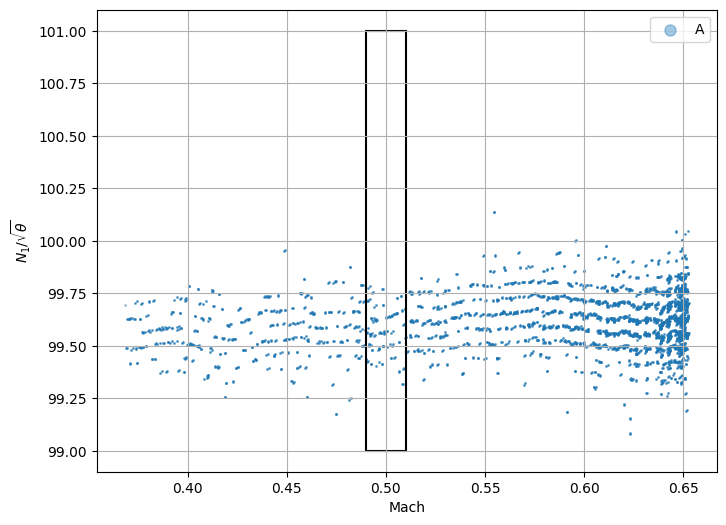

In [28]:
df_diag = split_train_test_val(make_df(''))
df_diag = df_diag[df_diag['faixa_altitude'] == 'A'].copy()
pontos, tol_m, tol_n = [(0.5, 100.0)], 0.01, 1.0

df_diag['ancora'] = _anchor_mask_por_condicao(df_diag, pontos, tol_m, tol_n).astype(bool)
print(df_diag.groupby(['faixa_altitude', 'type'])['ancora'].sum())

fig, ax = plt.subplots(figsize=(8, 6))
for fa, g in df_diag.groupby('faixa_altitude'):
    ax.scatter(g['Mach'], g['N1_over_sqrt_theta'], s=1, label=fa, alpha=0.4)
for m0, n0 in pontos:
    ax.add_patch(plt.Rectangle((m0 - tol_m, n0 - tol_n), 2 * tol_m, 2 * tol_n,
                               fill=False, edgecolor='k', linewidth=1.5))
ax.set_xlabel('Mach'); ax.set_ylabel(r'$N_1/\sqrt{\theta}$')
ax.legend(markerscale=8); ax.grid()
plt.show()

In [36]:
FEATURES1 = ['Mach', 'N1_over_sqrt_theta']
FEATURES2 = ['Mach2', 'NZ_W_dlt_Mach_sqr']
TARGETS   = ['Hdot_W_V_dlt']

# seeds = [0, 1, 2]
# # ---------------- Desenho LHS ----------------
# N_LHS          = 64
# LHS_SEED       = 0
# # CAMADAS_OPTS   = [3,4,5,6,7]
# # NEURONIOS_OPTS = [110,120,130]
# CAMADAS_Z1_OPTS   = [2,4,6,8,10]
# NEURONIOS_Z1_OPTS = [5,10,20,50,80]
# CAMADAS_Z2_OPTS   = CAMADAS_Z1_OPTS 
# NEURONIOS_Z2_OPTS = NEURONIOS_Z1_OPTS
# LAMBDA_ANCHOR_RANGE   = (1e-3, 1e3)   # amostrado em escala log
# ANCHOR_FRACTION_RANGE = (0.01, 0.2)   # amostrado em escala linear
# LAMBDA_MONO_NG = (1e-1, 1e4)   # tupla -> amostrado em escala log
# LAMBDA_MONO_T  = 0             # número -> valor fixo (pode ser 0)
# tipo_dados = ''

seeds = [0, 1, 2]
# ---------------- Desenho LHS ----------------
N_LHS          = 16
# LHS_SEED       = 0
CAMADAS_Z1_OPTS   = [2,4,6,8,10,12]
NEURONIOS_Z1_OPTS = [5,10,20,50,80,100,120]
CAMADAS_Z2_OPTS   = CAMADAS_Z1_OPTS
NEURONIOS_Z2_OPTS = NEURONIOS_Z1_OPTS
LAMBDA_ANCHOR_RANGE   = 0   # amostrado em escala log
ANCHOR_FRACTION_RANGE = 0   # amostrado em escala linear
LAMBDA_MONO_NG = (1e-1, 1e4)   # tupla -> amostrado em escala log
LAMBDA_MONO_T  = 0             # número -> valor fixo (pode ser 0)
tipo_dados = ''

nome_iteracao = 'lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr'
folder = 'Grid_Searches/' + nome_iteracao
LOTE = 'L0'    # nome do lote adicionado nesta rodada (use 'L2' numa próxima extensão)
LHS_SEED       = 0

In [37]:
def amostrar_log(faixa, u_col):
    """faixa: número (valor fixo, inclusive 0) ou tupla (lo, hi) para amostragem log."""
    if np.isscalar(faixa):
        return np.full(len(u_col), float(faixa))
    lo, hi = np.log10(faixa[0]), np.log10(faixa[1])
    return 10 ** (lo + u_col * (hi - lo))

def gerar_desenho_lhs(n, seed):
    d = 8
    try:
        sampler = qmc.LatinHypercube(d=d, optimization='random-cd', rng=np.random.default_rng(seed))
    except TypeError:  # SciPy < 1.15
        sampler = qmc.LatinHypercube(d=d, optimization='random-cd', seed=seed)
    u = sampler.random(n)
    # af_lo, af_hi = ANCHOR_FRACTION_RANGE
    return pd.DataFrame({
        'lhs_id':          np.arange(n),
        'camadas_z1':      [CAMADAS_Z1_OPTS[int(x * len(CAMADAS_Z1_OPTS))] for x in u[:, 0]],
        'neuronios_z1':    [NEURONIOS_Z1_OPTS[int(x * len(NEURONIOS_Z1_OPTS))] for x in u[:, 1]],
        'camadas_z2':      [CAMADAS_Z2_OPTS[int(x * len(CAMADAS_Z2_OPTS))] for x in u[:, 2]],
        'neuronios_z2':    [NEURONIOS_Z2_OPTS[int(x * len(NEURONIOS_Z2_OPTS))] for x in u[:, 3]],
        'lambda_anchor':   amostrar_log(LAMBDA_ANCHOR_RANGE, u[:, 4]),
        'anchor_fraction': amostrar_log(ANCHOR_FRACTION_RANGE, u[:, 5]),
        # 'anchor_fraction': np.round(af_lo + u[:, 5] * (af_hi - af_lo), 5),
        'lambda_mono_ng':  amostrar_log(LAMBDA_MONO_NG, u[:, 6]),
        'lambda_mono_t':   amostrar_log(LAMBDA_MONO_T, u[:, 7]),
    }).round({'lambda_anchor': 6, 'lambda_mono_ng': 6, 'lambda_mono_t': 6})


evaluated_set = 'test'
dot_size = 1
time_intervals = {
    '039_2013_VIN_FND': (5e4, 7e4),
    '040_2013_ASO_VTO': (0, 5e4),
    '041_2013_GEO_AIR': (0, 1e5),
    '042_2013_VAU_FTR': (0, 8e4),
}

OUT_DIR = f'{folder}/figures/grid_search_diagnostico'
os.makedirs(OUT_DIR, exist_ok=True)

ARQ_DESENHO = f'{folder}/desenho_lhs.csv'

if not os.path.isfile(ARQ_DESENHO):
    desenho = gerar_desenho_lhs(N_LHS, LHS_SEED)
    desenho['lote'] = LOTE
    desenho.to_csv(ARQ_DESENHO, index=False)
    print(f'[DESENHO LHS] gerado e salvo em {ARQ_DESENHO} ({len(desenho)} pontos)')
else:
    desenho = pd.read_csv(ARQ_DESENHO)
    if 'lote' not in desenho.columns:
        desenho['lote'] = 'L0'                       # desenho original, sem coluna de lote
    if (desenho['lote'] == LOTE).any():
        print(f'[DESENHO LHS] carregado ({len(desenho)} pontos; lote {LOTE} já incluído)')
    else:
        desenho.to_csv(f'{folder}/desenho_lhs_antes_{LOTE}.csv', index=False)   # backup
        novo = gerar_desenho_lhs(N_LHS, LHS_SEED)
        novo['lhs_id'] += desenho['lhs_id'].max() + 1     # ids novos: sem colisão com as pastas antigas
        novo['lote'] = LOTE
        desenho = pd.concat([desenho, novo], ignore_index=True)
        desenho.to_csv(ARQ_DESENHO, index=False)
        print(f'[DESENHO LHS] lote {LOTE} adicionado: agora são {len(desenho)} pontos')

assert desenho['lhs_id'].is_unique, 'lhs_id duplicado no desenho!'

metricas = []
pdf_story = []

MAX_LARGURA_CM = 18.0
MAX_ALTURA_CM = 24.0

n_treinadas, n_puladas = 0, 0

for _, ponto in desenho.iterrows():
    for seed in seeds:
        lhs_id          = int(ponto['lhs_id'])
        # camada          = int(ponto['camadas'])
        # neuronio        = int(ponto['neuronios'])
        camada_z1   = int(ponto['camadas_z1'])
        neuronio_z1 = int(ponto['neuronios_z1'])
        camada_z2   = int(ponto['camadas_z2'])
        neuronio_z2 = int(ponto['neuronios_z2'])
        lambda_mono_ng     = float(ponto['lambda_mono_ng'])
        lambda_mono_t      = float(ponto['lambda_mono_t'])
        lambda_anchor   = float(ponto['lambda_anchor'])
        anchor_fraction = float(ponto['anchor_fraction'])

        combo_nome = f's{seed}_lhs{lhs_id:03d}'
        combo_dir = os.path.join(OUT_DIR, combo_nome)
        titulo = (f'Seed: {seed} | LHS #{lhs_id} | Z1: {camada_z1}x{neuronio_z1} | Z2: {camada_z2}x{neuronio_z2} '
                  f'| lambda_anchor: {lambda_anchor:.3g} | anchor_fraction: {anchor_fraction:.3f}'
                  f' | lambda_mono_ng: {lambda_mono_ng:.3g} | lambda_mono_t: {lambda_mono_t:.3g}')
        
        # ---------------- Verificação de checkpoint ----------------
        if checkpoint_completo(combo_dir):
            print(f'[CHECKPOINT ENCONTRADO] {combo_nome}: rede já treinada, pulando treino.')
            metricas.extend(pd.read_csv(os.path.join(combo_dir, ARQ_METRICAS)).to_dict('records'))
            adicionar_pagina_pdf(pdf_story, titulo, os.path.join(combo_dir, ARQ_PAGINA),
                                    MAX_LARGURA_CM, MAX_ALTURA_CM)
            n_puladas += 1
            continue
        elif os.path.isdir(combo_dir):
            print(f'[CHECKPOINT INCOMPLETO] {combo_nome}: pasta existe, mas o treino foi interrompido. Treinando de novo...')
        else:
            print(f'[CHECKPOINT NÃO ENCONTRADO] {combo_nome}: treinando...')
        os.makedirs(combo_dir, exist_ok=True)

        architecture = {
            'neurons_z1': neuronio_z1,
            'camadas_ocultas_z1': camada_z1,
            'neurons_z2': neuronio_z2,
            'camadas_ocultas_z2': camada_z2,
            'activation': 'relu',
            'dropout': 0,
        }
        hyperparameters = {
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': 200,
            'batch_size': 128,
            'patience': 20,
            'lambda_mono_ng': lambda_mono_ng,
            'lambda_mono_t': lambda_mono_t,
            'lambda_anchor': lambda_anchor,
            'anchor_points': [(0.5, 100.0)],   # lista de (Mach, N1/sqrt(theta))
            'anchor_tol_mach': 0.01,
            'anchor_tol_n1': 1.0,
        }

        df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
            tipo_dados=tipo_dados,
            features1=FEATURES1,
            features2=FEATURES2,
            targets=TARGETS,
            mode='train',
            architecture=architecture,
            hyperparameters=hyperparameters,
            seed=seed,
            evaluated_set=evaluated_set,
            plot=False
        )

        extractor = keras.Model(
            inputs=model.inputs,
            outputs=[
                model.get_layer('NN1_output').output,  # Z1
                model.get_layer('NN2_output').output,  # Z2
                model.output                           # Y (Z1 - Z2)
            ]
        )

        features1_scaled = [f + '_scaled' for f in FEATURES1]
        features2_scaled = [f + '_scaled' for f in FEATURES2]

        X1_all = np.array(df[features1_scaled]).astype(np.float32)
        X2_all = np.array(df[features2_scaled]).astype(np.float32)

        z1_vals, z2_vals, y_vals = extractor.predict([X1_all, X2_all])

        df['Z1_scaled'] = z1_vals.flatten()
        df['Z2_scaled'] = z2_vals.flatten()

        df['Z1_minus_Z2'] = scaler_y.inverse_transform(y_vals).flatten()
        df['Z1'] = scaler_y.inverse_transform(z1_vals).flatten()
        df['Z2'] = df['Z1'] - df['Z1_minus_Z2']

        df['Tn_dlt'] = (df['T'] * np.cos(np.radians(df['Alfa'])) / df['delta']) * 0.453592
        df['D_dlt'] = df['Tn_dlt'] - df['Hdot_W_V_dlt']

        c_offset, std_res_anc, n_anc = calcular_offset_ancoras(df, hyperparameters)
        df['Z1'] += c_offset
        df['Z2'] += c_offset
        print(f"Offset das âncoras: c = {c_offset:.1f} kgf | desvio do resíduo = {std_res_anc:.1f} kgf | n = {n_anc}")

        # --- curva de loss desta combinação ---
        plt.figure(figsize=(8, 4))
        plt.plot(training_history.history['loss'], label='Train')
        plt.plot(training_history.history['val_loss'], label='Validation')
        plt.xlabel('Epoch'); plt.ylabel('Loss (dados)'); plt.legend(); plt.grid()
        plt.savefig(os.path.join(combo_dir, 'loss.png'), dpi=120); plt.close()

        subset = df[df['type'] == evaluated_set]

        voos_presentes = [f for f in subset['filename'].unique() if f in time_intervals]
        n_voos = len(voos_presentes)
        n_metricas = 4

        altura_total_in = 5.5 * n_metricas
        largura_total_in = altura_total_in * (MAX_LARGURA_CM / MAX_ALTURA_CM)
        fig_pdf, axs_pdf = plt.subplots(n_metricas, n_voos, figsize=(largura_total_in, altura_total_in), squeeze=False)

        metricas_combo = []

        for col_idx, filename in enumerate(voos_presentes):
            grupo = subset[subset['filename'] == filename]
            t0, t = time_intervals[filename]
            mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
            grupo = grupo[mask].copy()

            erroH = abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']).mean()
            erroD = abs(grupo['D_dlt'] - grupo['Z2']).mean()
            erroT = abs(grupo['Tn_dlt'] - grupo['Z1']).mean()

            metricas_combo.append({
                'seed': seed,
                'camadas_z1': camada_z1, 'neuronios_z1': neuronio_z1,
                'camadas_z2': camada_z2, 'neuronios_z2': neuronio_z2,
                'lambda_mono_ng': lambda_mono_ng, 'lambda_mono_t': lambda_mono_t,
                'lambda_anchor': lambda_anchor, 'anchor_fraction': anchor_fraction,
                'filename': filename,
                'erroH': erroH, 'erroD': erroD, 'erroT': erroT,
                'lhs_id': lhs_id
            })

            base = os.path.join(combo_dir, filename)

            # --- linha 0: pred vs real ---
            plt.figure(figsize=(10, 4))
            plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
            plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'], s=dot_size, label='Hdot_W_V_dlt')
            plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
            plt.savefig(f'{base}_pred_vs_real.png', dpi=120); plt.close()

            ax = axs_pdf[0, col_idx]
            ax.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size*3, label='Hdot_W_V_dlt_pred')
            ax.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'], s=dot_size*3, label='Hdot_W_V_dlt')
            ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)
            ax.set_title(filename, fontsize=11, fontweight='bold')

            # --- linha 1: erro absoluto ---
            plt.figure(figsize=(10, 4))
            plt.scatter(grupo['TEMPO_SAD'], abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']), s=dot_size,
                        label='|Hdot_W_V_dlt_pred - Hdot_W_V_dlt|')
            plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
            plt.savefig(f'{base}_erro_abs.png', dpi=120); plt.close()

            ax = axs_pdf[1, col_idx]
            ax.scatter(grupo['TEMPO_SAD'], abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']), s=dot_size*3,
                        label='|erro|')
            ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)

            # --- linha 2: Z1 vs Tn_dlt ---
            plt.figure(figsize=(10, 4))
            plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'], s=dot_size, label='Z1')
            plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
            plt.legend(markerscale=5); plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
            plt.xlabel('DAQ Time (s)'); plt.grid()
            plt.savefig(f'{base}_Z1_vs_Tn.png', dpi=120); plt.close()

            ax = axs_pdf[2, col_idx]
            ax.scatter(grupo['TEMPO_SAD'], grupo['Z1'], s=dot_size*3, label='Z1')
            ax.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size*3, label=r'Tcos$\alpha$/$\delta$')
            ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)

            # --- linha 3: Z2 vs D_dlt ---
            plt.figure(figsize=(10, 4))
            plt.scatter(grupo['TEMPO_SAD'], grupo['Z2'], s=dot_size, label='Z2')
            plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label=r'D/$\delta$')
            plt.legend(markerscale=5); plt.ylabel(r'Z2 and D/$\delta$ (kgf)')
            plt.xlabel('DAQ Time (s)'); plt.grid()
            plt.savefig(f'{base}_Z2_vs_D.png', dpi=120); plt.close()

            ax = axs_pdf[3, col_idx]
            ax.scatter(grupo['TEMPO_SAD'], grupo['Z2'], s=dot_size*3, label='Z2')
            ax.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size*3, label=r'D/$\delta$')
            ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)

        row_labels = ['Pred vs Real', '|Erro|', 'Z1 vs Tn', 'Z2 vs D']
        for row_idx, label in enumerate(row_labels):
            axs_pdf[row_idx, 0].set_ylabel(label, fontsize=11, fontweight='bold')

        fig_pdf.suptitle(titulo, fontsize=16)
        fig_pdf.tight_layout(rect=[0, 0, 1, 0.97])
        page_img_path = os.path.join(combo_dir, ARQ_PAGINA)
        fig_pdf.savefig(page_img_path, dpi=110)
        plt.close(fig_pdf)

        # ---------------- Salva o checkpoint (marcador por último) ----------------
        salvar_checkpoint(
            combo_dir,
            model=model,
            training_history=training_history,
            scalers={'scaler_x1': scaler_x1, 'scaler_x2': scaler_x2, 'scaler_y': scaler_y},
            metricas_combo=metricas_combo,
            config={
                'seed': seed,
                'features1': FEATURES1,
                'features2': FEATURES2,
                'targets': TARGETS,
                'evaluated_set': evaluated_set,
                'architecture': architecture,
                'hyperparameters': hyperparameters,
                'lhs_id': lhs_id,
                'desenho': {'N': int(len(desenho)), 'lhs_seed': LHS_SEED},
            }
        )
        print(f'[CHECKPOINT SALVO] {combo_nome}')

        metricas.extend(metricas_combo)
        adicionar_pagina_pdf(pdf_story, titulo, page_img_path, MAX_LARGURA_CM, MAX_ALTURA_CM)
        n_treinadas += 1

        # CSV global parcial: dá pra acompanhar os resultados sem esperar o fim
        pd.DataFrame(metricas).to_csv(f'{folder}/metricas_diagnostico_parcial.csv', index=False)

        del df, model, extractor, training_history, results
        gc.collect()

print(f'\nResumo: {n_treinadas} redes treinadas agora, {n_puladas} recuperadas de checkpoint.')

df_metricas = pd.DataFrame(metricas)
df_metricas.to_csv(f'{folder}/metricas_diagnostico.csv', index=False)
print(f"Salvo resumo com {len(df_metricas)} linhas em {folder}/metricas_diagnostico.csv")

doc = SimpleDocTemplate(
    f'{folder}/relatorio_diagnostico_grid_search.pdf',
    pagesize=A4,
    topMargin=1.5 * cm, bottomMargin=1.5 * cm, leftMargin=1.5 * cm, rightMargin=1.5 * cm
)
doc.build(pdf_story)
print(f"PDF salvo em {folder}/relatorio_diagnostico_grid_search.pdf com {n_treinadas + n_puladas} páginas")

[DESENHO LHS] gerado e salvo em Grid_Searches/lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr/desenho_lhs.csv (16 pontos)
[CHECKPOINT NÃO ENCONTRADO] s0_lhs000: treinando...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Âncoras (treino): 224 pontos (0.80%)
Treinando modelo...
1074/1074 ━━━━━━━━━━━━━━━━━━━━ 1s 740us/step
1074/1074 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Offset das âncoras: c = 402.2 kgf | desvio do resíduo = 17.2 kgf | n = 224
[CHECKPOINT SALVO] s0_lhs000
[CHECKPOINT NÃO ENCONTRADO] s1_lhs000: treinando...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Âncoras (treino): 224 pontos (0.80%)
Treinando modelo...
1074/1074 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1074/1074 ━━━━━━━━━━━━━━━━━━━━ 1s 836us/step
Offset das âncoras: c = 514.6 kgf | desvio do resíduo = 15.5 kgf | n = 224
[CHECKPOINT SALVO] s1_lhs000
[CHECKPOINT NÃO ENCONTRADO] s2_lhs000: treinando...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


... (87 outputs left out)

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Âncoras (treino): 224 pontos (0.80%)
Treinando modelo...
1074/1074 ━━━━━━━━━━━━━━━━━━━━ 1s 704us/step
1074/1074 ━━━━━━━━━━━━━━━━━━━━ 1s 706us/step
Offset das âncoras: c = 291.0 kgf | desvio do resíduo = 10.1 kgf | n = 224
[CHECKPOINT SALVO] s1_lhs015
[CHECKPOINT NÃO ENCONTRADO] s2_lhs015: treinando...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Âncoras (treino): 224 pontos (0.80%)
Treinando modelo...
1074/1074 ━━━━━━━━━━━━━━━━━━━━ 1s 682us/step
1074/1074 ━━━━━━━━━━━━━━━━━━━━ 1s 692us/step
Offset das âncoras: c = 453.1 kgf | desvio do resíduo = 16.8 kgf | n = 224
[CHECKPOINT SALVO] s2_lhs015

Resumo: 48 redes treinadas agora, 0 recuperadas de checkpoint.
Salvo resumo com 48 linhas em Grid_Searches/lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr/metricas_diagnostico.csv
PDF salvo em Grid_Searches/lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr/relatorio_diagnostico_grid_search.pdf com 48 páginas


In [38]:
# ---------------- Configuração ----------------
PASTA_BASE = 'Grid_Searches'

PASTAS = [
    # "lhs_anchoring_27092026_Mach1_NZ_LHS",
    # "lhs_anchoring_27092026_Mach1_NZsqr_LHS",
    # "lhs_anchoring_27092026_Mach2_NZ_LHS",
    # "lhs_anchoring_27092026_Mach2_NZsqr_LHS",
    # "lhs_anchoring_Mach2_NZsqr_lambdaT",
    # "lhs_anchoring_Mach2_NZsqr_lambdaNG",
    # "lhs_anchoring_Mach1_NZ_lambdaNG",
    nome_iteracao
]
CONJUNTOS  = ['val']     # conjuntos avaliados; pode incluir 'test' (vira outra linha, coluna 'conjunto')
TIPO_DADOS = ''          # o mesmo tipo_dados usado no analyze() do treino (o config.json não guarda isso)

# ARQ_SAIDA = os.path.join(PASTA_BASE, 'metricas_' + '_'.join(CONJUNTOS) + '_todos_modelos.csv')
ARQ_SAIDA = os.path.join(PASTA_BASE, 'metricas_' + '_'.join(CONJUNTOS) + '_' + nome_iteracao + '.csv')

time_intervals = {
    '039_2013_VIN_FND': (5e4, 7e4),
    '040_2013_ASO_VTO': (0, 5e4),
    '041_2013_GEO_AIR': (0, 1e5),
    '042_2013_VAU_FTR': (0, 8e4),
}

# ---------------- Funções ----------------
def listar_modelos(pasta_base, pastas):
    """Procura, dentro de cada pasta da lista, todas as subpastas de redes já treinadas
    (as que têm o marcador CONCLUIDO.json, o modelo, os scalers e o config)."""
    necessarios = [ARQ_CONCLUIDO, ARQ_MODELO, ARQ_SCALERS, ARQ_CONFIG]
    achados = []
    for pasta in pastas:
        for dirpath, _, _ in os.walk(os.path.join(pasta_base, pasta)):
            if all(os.path.isfile(os.path.join(dirpath, a)) for a in necessarios):
                achados.append((pasta, dirpath))
    return sorted(achados, key=lambda x: x[1])


_cache_df = {}
def obter_df_base(tipo_dados):
    """Monta o dataframe uma única vez (split determinístico, igual ao do treino)."""
    if tipo_dados not in _cache_df:
        df = make_df(tipo_dados)
        df = split_train_test_val(df)
        df['Tn_dlt'] = (df['T'] * np.cos(np.radians(df['Alfa'])) / df['delta']) * 0.453592
        df['D_dlt'] = df['Tn_dlt'] - df['Hdot_W_V_dlt']
        _cache_df[tipo_dados] = df.copy()   # mantém o treino: necessário para o offset das âncoras
    return _cache_df[tipo_dados]


def avaliar_modelo(combo_dir, pasta):
    model = keras.models.load_model(os.path.join(combo_dir, ARQ_MODELO))
    scalers = joblib.load(os.path.join(combo_dir, ARQ_SCALERS))
    with open(os.path.join(combo_dir, ARQ_CONFIG), encoding='utf-8') as f:
        config = json.load(f)

    features1, features2 = config['features1'], config['features2']
    scaler_x1, scaler_x2, scaler_y = scalers['scaler_x1'], scalers['scaler_x2'], scalers['scaler_y']
    arq, hp = config['architecture'], config['hyperparameters']

    df = obter_df_base(config.get('tipo_dados', TIPO_DADOS)).copy()

    # Escalonamento com os scalers SALVOS (ajustados no treino), sem refazer o fit
    X1 = scaler_x1.transform(df[features1]).astype(np.float32)
    X2 = scaler_x2.transform(df[features2]).astype(np.float32)

    extractor = keras.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer('NN1_output').output,  # Z1
            model.get_layer('NN2_output').output,  # Z2
            model.output,                          # Y (Z1 - Z2)
        ]
    )
    z1_s, z2_s, y_s = extractor.predict([X1, X2], verbose=0)

    df['Hdot_W_V_dlt_pred'] = scaler_y.inverse_transform(y_s).flatten()
    df['Z1'] = scaler_y.inverse_transform(z1_s).flatten()
    df['Z2'] = df['Z1'] - df['Hdot_W_V_dlt_pred']

    c_offset, std_res_anc, n_anc = calcular_offset_ancoras(df, hp)
    df['Z1'] += c_offset
    df['Z2'] += c_offset

    meta = {
        'pasta': pasta,
        'combo': os.path.basename(combo_dir),
        'seed': config.get('seed'),
        'lhs_id': config.get('lhs_id'),
        'camadas_z1':   arq.get('camadas_ocultas_z1', arq.get('camadas_ocultas')),
        'neuronios_z1': arq.get('neurons_z1', arq.get('neurons')),
        'camadas_z2':   arq.get('camadas_ocultas_z2', arq.get('camadas_ocultas')),
        'neuronios_z2': arq.get('neurons_z2', arq.get('neurons')),
        'lambda_mono_ng': hp.get('lambda_mono_ng', hp.get('lambda_mono', 1.0)),
        'lambda_mono_t': hp.get('lambda_mono_t', 0.0),
        'lambda_anchor': hp.get('lambda_anchor', 0.0),
        'anchor_fraction': hp.get('anchor_fraction', 0.01),
        'c_offset': c_offset,
        'std_res_ancoras': std_res_anc,
        'n_ancoras': n_anc,
    }

    linhas = []
    for conjunto in CONJUNTOS:
        subset = df[df['type'] == conjunto]
        voos = [f for f in subset['filename'].unique() if f in time_intervals]

        for filename in voos:
            grupo = subset[subset['filename'] == filename]
            t0, t = time_intervals[filename]
            grupo = grupo[(grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)].copy()
            if grupo.empty:
                continue

            # mesmo alinhamento de offset de Z1/Z2 usado no grid search
            k = min(min(grupo['Z1']), min(grupo['Z2']))
            grupo['Z1'], grupo['Z2'] = (
                grupo['Z1'] - k + (grupo['Hdot_W_V_dlt_pred'] - (grupo['Z1'] - grupo['Z2'])).mean(),
                grupo['Z2'] - k
            )

            linhas.append({
                **meta,
                'conjunto': conjunto,
                'filename': filename,
                'n_pontos': len(grupo),
                'erroH': abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']).mean(),
                'erroD': abs(grupo['D_dlt'] - grupo['Z2']).mean(),
                'erroT': abs(grupo['Tn_dlt'] - grupo['Z1']).mean(),
                'stdZ1': grupo['Z1'].std(),
                'stdT':  grupo['Tn_dlt'].std(),
            })
    return linhas


# ---------------- Execução ----------------
modelos = listar_modelos(PASTA_BASE, PASTAS)
print(f'{len(modelos)} modelos treinados encontrados.')

linhas_todas, falhas = [], []
for i, (pasta, combo_dir) in enumerate(modelos, start=1):
    print(f'[{i}/{len(modelos)}] {os.path.relpath(combo_dir, PASTA_BASE)}')
    try:
        linhas_todas.extend(avaliar_modelo(combo_dir, pasta))
    except Exception as e:
        falhas.append((combo_dir, repr(e)))
        print(f'   FALHOU: {e!r}')
    finally:
        keras.backend.clear_session()
        gc.collect()

df_avaliacao = pd.DataFrame(linhas_todas)
df_avaliacao.to_csv(ARQ_SAIDA, index=False)
print(f'\nSalvo: {ARQ_SAIDA} ({len(df_avaliacao)} linhas, {len(modelos) - len(falhas)} modelos avaliados)')
if falhas:
    print(f'{len(falhas)} modelos falharam:')
    for d, erro in falhas:
        print(f'  - {d}: {erro}')

48 modelos treinados encontrados.
[1/48] lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr\figures\grid_search_diagnostico\s0_lhs000

[2/48] lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr\figures\grid_search_diagnostico\s0_lhs001
[3/48] lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr\figures\grid_search_diagnostico\s0_lhs002
[4/48] lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr\figures\grid_search_diagnostico\s0_lhs003
[5/48] lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr\figures\grid_search_diagnostico\s0_lhs004
[6/48] lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr\figures\grid_search_diagnostico\s0_lhs005
[7/48] lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr\figures\grid_search_diagnostico\s0_lhs006
[8/48] lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr\figures\grid_search_diagnostico\s0_lhs007
[9/48] lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr\figures\grid_search_diagnostico\s0_lhs008
[10/48] lhs_Mach_NG_Anchoring_Mach2_NZ_W_dlt_Mach_sqr\figures\grid_search_diagnostico\s0_lhs009
[11/48] lhs_Ma

16 configurações (3 a 3 seeds cada)


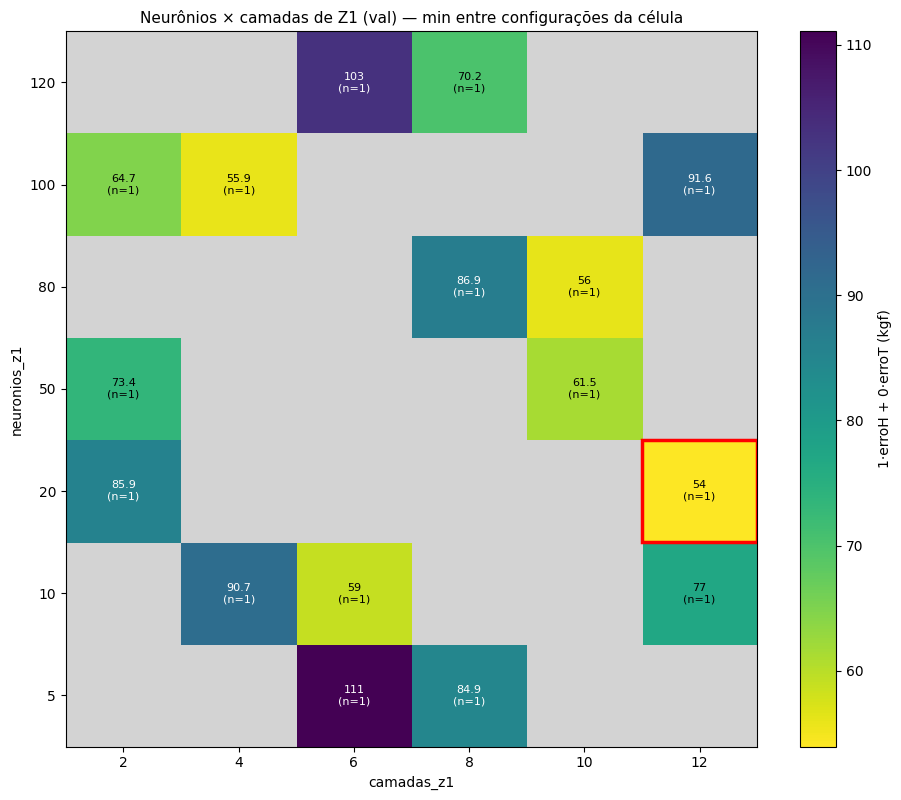

Melhor célula: neuronios_z1 = 20, camadas_z1 = 12 -> 53.95


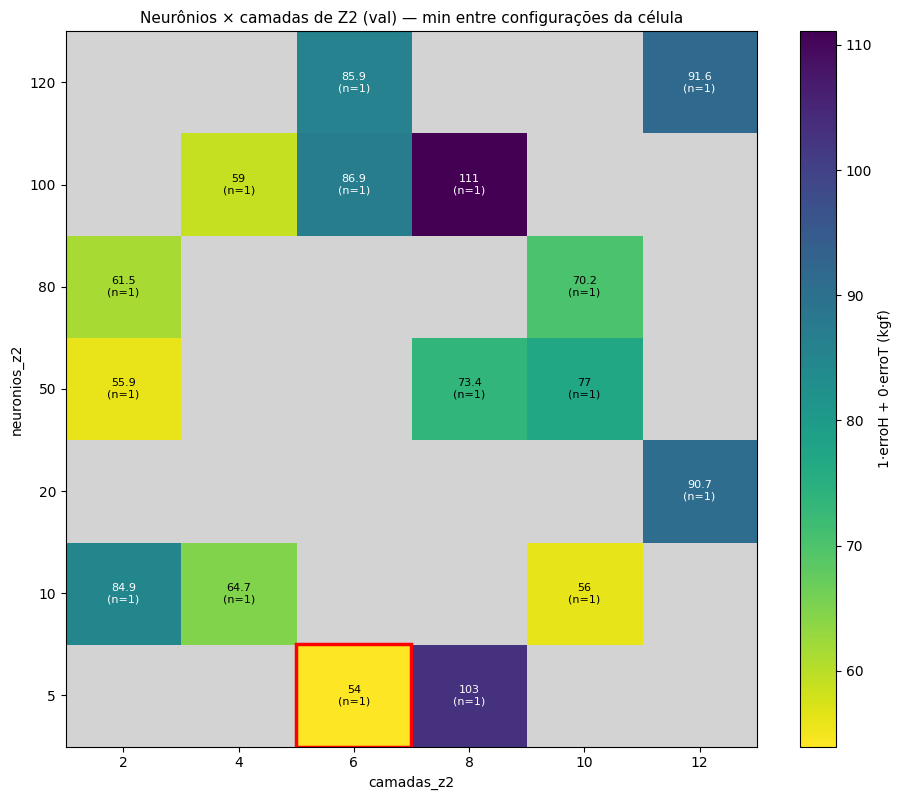

Melhor célula: neuronios_z2 = 5, camadas_z2 = 6 -> 53.95


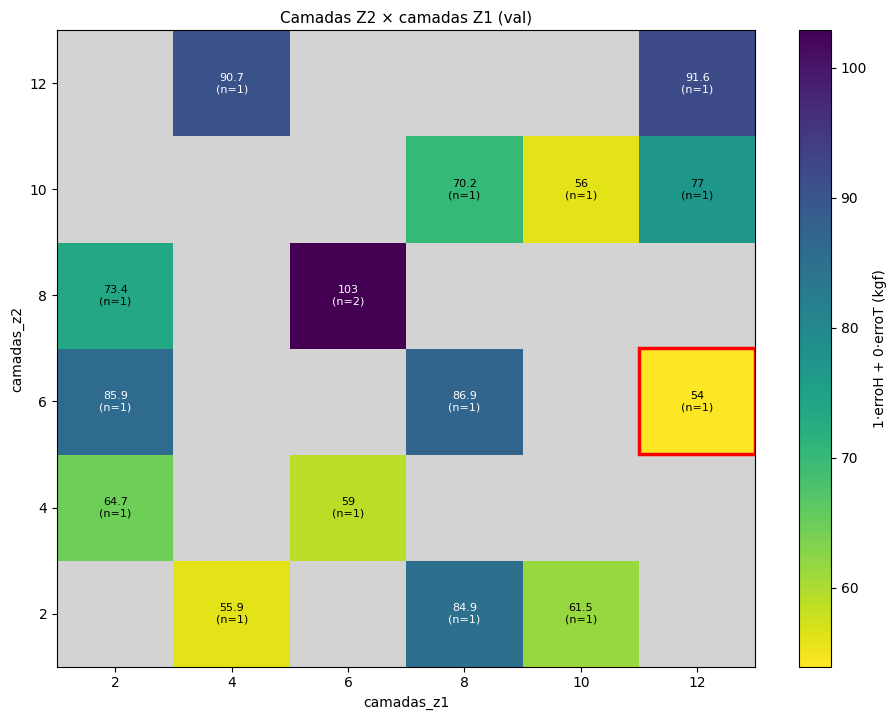

Melhor célula: camadas_z2 = 6, camadas_z1 = 12 -> 53.95


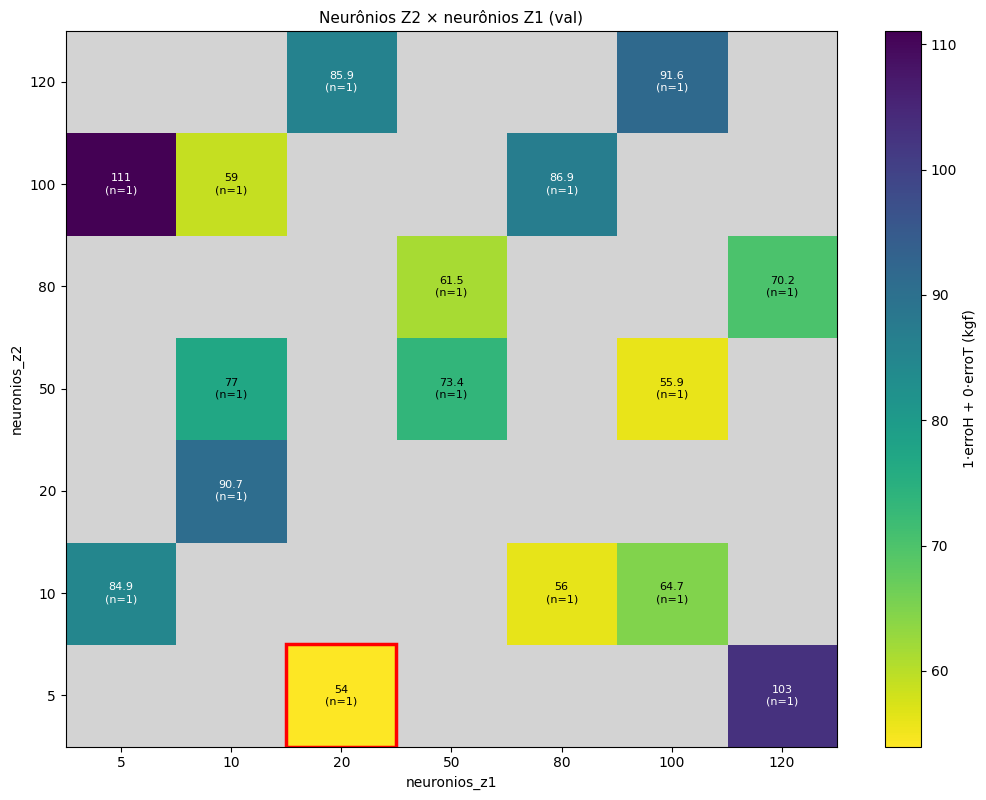

Melhor célula: neuronios_z2 = 5, neuronios_z1 = 20 -> 53.95


In [39]:
# ---------------- Configuração ----------------
# CSV_METRICAS  = 'Grid_Searches/metricas_val_todos_modelos.csv'   # saída da célula de avaliação
# CSV_METRICAS  = 'Grid_Searches/metricas_val_lhs_anchoring_Mach2_NZsqr_lambdaT.csv'   # saída da célula de avaliação
# CSV_METRICAS  = 'Grid_Searches/metricas_val_lhs_anchoring_Mach2_NZsqr_lambdaNG.csv'   # saída da célula de avaliação
# CSV_METRICAS  = 'Grid_Searches/metricas_val_lhs_anchoring_Mach2_NZsqr_lambdaNG.csv'   # saída da célula de avaliação
# CSV_METRICAS  = 'Grid_Searches/metricas_val_lhs_anchoring_Mach1_NZ_lambdaNG.csv'   # saída da célula de avaliação
# CSV_METRICAS  = 'Grid_Searches/Voo_Completo/metricas_val_lhs_anchoring_Mach1_NZ_lambdaNG.csv'   # saída da célula de avaliação
# CSV_METRICAS  = 'Grid_Searches/metricas_valteste.csv'   # saída da célula de avaliação
CSV_METRICAS  = 'Grid_Searches/metricas_val_' + nome_iteracao + '.csv'
CONJUNTO      = 'val'
PASTAS_FILTRO = None            # None = todas; ou uma lista, ex.: ['lhs_anchoring_Mach2_NZsqr_lambdaNG']
PESO_H, PESO_T = 1, 0      # score = PESO_H*erroH + PESO_T*erroT
AGREGACAO     = 'min'           # como juntar configurações que caem na mesma célula: 'min' | 'mean' | 'median'
ESCALA_LOG    = False           # True = escala de cor logarítmica (útil se houver outliers muito altos)

# Colunas que identificam uma configuração (sem a seed)
CHAVE_CONFIG = ['pasta', 'camadas_z1', 'neuronios_z1', 'camadas_z2', 'neuronios_z2',
                'lambda_mono_ng', 'lambda_mono_t', 'lambda_anchor', 'anchor_fraction']


# ---------------- Funções ----------------
def carregar_configuracoes(csv, conjunto, pastas, peso_h, peso_t):
    """Uma linha por configuração: score médio sobre seeds (e voos)."""
    df = pd.read_csv(csv)
    df = df[df['conjunto'] == conjunto]
    if pastas is not None:
        df = df[df['pasta'].isin(pastas)]

    # Compatibilidade com CSVs antigos (mesma arquitetura em Z1 e Z2)
    for sub in ('z1', 'z2'):
        for base in ('camadas', 'neuronios'):
            col = f'{base}_{sub}'
            if col not in df.columns:
                df[col] = df[base] if base in df.columns else np.nan
            elif base in df.columns:
                df[col] = df[col].fillna(df[base])

    df = df.dropna(subset=['erroH', 'erroT']).copy()
    df['score'] = peso_h * df['erroH'] + peso_t * df['erroT']
    return (df.groupby(CHAVE_CONFIG, dropna=False)
              .agg(score=('score', 'mean'), n_seeds=('seed', 'nunique'))
              .reset_index())


def _discretizar(serie, n_bins, log):
    """Agrupa um parâmetro contínuo em faixas; devolve o centro de cada faixa."""
    lo, hi = serie.min(), serie.max()
    bordas = np.geomspace(lo, hi, n_bins + 1) if log else np.linspace(lo, hi, n_bins + 1)
    cat = pd.cut(serie, bins=bordas, include_lowest=True)
    centros = np.sqrt(bordas[:-1] * bordas[1:]) if log else (bordas[:-1] + bordas[1:]) / 2
    mapa = dict(zip(cat.cat.categories, centros))
    return cat.map(mapa).astype(float)


def plotar_heatmap(cfg, eixo_y, eixo_x, agregacao='min', bins=None, escala_log=False,
                   rotulo_score='score', titulo=None, arquivo=None):
    bins = bins or {}
    d = cfg.copy()
    for col in (eixo_y, eixo_x):
        if col in bins:
            d[col] = _discretizar(d[col], bins[col], log=(col == 'lambda_anchor'))

    tab = d.pivot_table(index=eixo_y, columns=eixo_x, values='score', aggfunc=agregacao).sort_index()
    cont = d.pivot_table(index=eixo_y, columns=eixo_x, values='score', aggfunc='count').reindex_like(tab)

    Z = np.ma.masked_invalid(tab.values.astype(float))
    cmap = plt.get_cmap('viridis_r').copy()
    cmap.set_bad('lightgray')
    norm = LogNorm(vmin=np.nanmin(tab.values), vmax=np.nanmax(tab.values)) if escala_log else None

    fig, ax = plt.subplots(figsize=(1.0 * tab.shape[1] + 3.5, 0.8 * tab.shape[0] + 2.5))
    im = ax.imshow(Z, origin='lower', aspect='auto', cmap=cmap, norm=norm)

    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            if np.isnan(v):
                continue
            cor = 'white' if im.norm(v) > 0.5 else 'black'
            ax.text(j, i, f'{v:.3g}\n(n={int(cont.values[i, j])})', ha='center', va='center',
                    fontsize=8, color=cor)

    # contorno vermelho na melhor célula
    iy, ix = np.unravel_index(np.nanargmin(tab.values), tab.shape)
    ax.add_patch(Rectangle((ix - 0.5, iy - 0.5), 1, 1, fill=False, edgecolor='red', lw=2.5))

    ax.set_xticks(range(tab.shape[1]))
    ax.set_xticklabels([f'{c:.3g}' for c in tab.columns])
    ax.set_yticks(range(tab.shape[0]))
    ax.set_yticklabels([f'{r:.3g}' for r in tab.index])
    ax.set_xlabel(eixo_x + (' (centro da faixa)' if eixo_x in bins else ''))
    ax.set_ylabel(eixo_y + (' (centro da faixa)' if eixo_y in bins else ''))
    ax.set_title(titulo or f'{rotulo_score} — {agregacao} por célula', fontsize=11)
    fig.colorbar(im, ax=ax, label=rotulo_score)

    fig.tight_layout()
    if arquivo:
        fig.savefig(arquivo, dpi=150, bbox_inches='tight')
    plt.show()

    print(f'Melhor célula: {eixo_y} = {tab.index[iy]:.3g}, {eixo_x} = {tab.columns[ix]:.3g} '
          f'-> {tab.values[iy, ix]:.4g}')
    return tab


# ---------------- Execução ----------------
cfg = carregar_configuracoes(CSV_METRICAS, CONJUNTO, PASTAS_FILTRO, PESO_H, PESO_T)
print(f'{len(cfg)} configurações ({cfg["n_seeds"].min()} a {cfg["n_seeds"].max()} seeds cada)')

rotulo = f'{PESO_H}·erroH + {PESO_T}·erroT (kgf)'
pasta_saida = os.path.dirname(CSV_METRICAS)

# Neurônios × camadas, uma figura por sub-rede
tabs_nc = {}
for sub, nome in (('z1', 'Z1'), ('z2', 'Z2')):
    tabs_nc[nome] = plotar_heatmap(
        cfg, eixo_y=f'neuronios_{sub}', eixo_x=f'camadas_{sub}',
        agregacao=AGREGACAO, escala_log=ESCALA_LOG, rotulo_score=rotulo,
        titulo=f'Neurônios × camadas de {nome} ({CONJUNTO}) — {AGREGACAO} entre configurações da célula',
        arquivo=os.path.join(pasta_saida, f'heatmap_neuronios_camadas_{nome}_{CONJUNTO}.png'),
    )

# Exemplo: interação entre as duas sub-redes (mesma grandeza em Z1 × Z2)
tab_camadas_z1z2 = plotar_heatmap(
    cfg, eixo_y='camadas_z2', eixo_x='camadas_z1',
    agregacao=AGREGACAO, escala_log=ESCALA_LOG, rotulo_score=rotulo,
    titulo=f'Camadas Z2 × camadas Z1 ({CONJUNTO})',
    arquivo=os.path.join(pasta_saida, f'heatmap_camadas_Z1_Z2_{CONJUNTO}.png'),
)
tab_neuronios_z1z2 = plotar_heatmap(
    cfg, eixo_y='neuronios_z2', eixo_x='neuronios_z1',
    agregacao=AGREGACAO, escala_log=ESCALA_LOG, rotulo_score=rotulo,
    titulo=f'Neurônios Z2 × neurônios Z1 ({CONJUNTO})',
    arquivo=os.path.join(pasta_saida, f'heatmap_neuronios_Z1_Z2_{CONJUNTO}.png'),
)

# # Exemplo: os dois parâmetros de ancoragem (contínuos no LHS, então agrupados em faixas)
# tab_ancora = plotar_heatmap(
#     cfg, eixo_y='anchor_fraction', eixo_x='lambda_anchor',
#     agregacao=AGREGACAO, escala_log=ESCALA_LOG, rotulo_score=rotulo,
#     bins={'anchor_fraction': 5, 'lambda_anchor': 6},
#     arquivo=os.path.join(pasta_saida, f'heatmap_ancoragem_{CONJUNTO}.png'),
# )

In [ ]:
# ---------------- Configuração ----------------
CSV_METRICAS  = 'Grid_Searches/metricas_val_lhs_anchoring_Mach2_NZsqr_lambdaT.csv'   # saída da célula de avaliação
CONJUNTO      = 'val'
PASTAS_FILTRO = None            # None = todas; ou uma lista, ex.: ['lhs_anchoring_Mach2_NZsqr_lambdaT']
PESO_H, PESO_T = 1, 0       # score = PESO_H*erroH + PESO_T*erroT
AGREGACAO     = 'min'           # como juntar configurações que caem na mesma célula: 'min' | 'mean' | 'median'
ESCALA_LOG    = False           # True = escala de cor logarítmica (útil se houver outliers muito altos)

# Colunas que identificam uma configuração (sem a seed)
CHAVE_CONFIG = ['pasta', 'camadas', 'neuronios', 'lambda_mono_ng', 'lambda_mono_t',
                'lambda_anchor', 'anchor_fraction']


# ---------------- Funções ----------------
def carregar_configuracoes(csv, conjunto, pastas, peso_h, peso_t):
    """Uma linha por configuração: score médio sobre seeds (e voos)."""
    df = pd.read_csv(csv)
    df = df[df['conjunto'] == conjunto]
    if pastas is not None:
        df = df[df['pasta'].isin(pastas)]
    df = df.dropna(subset=['erroH', 'erroT']).copy()
    df['score'] = peso_h * df['erroH'] + peso_t * df['erroT']
    return (df.groupby(CHAVE_CONFIG, dropna=False)
              .agg(score=('score', 'mean'), n_seeds=('seed', 'nunique'))
              .reset_index())


def _discretizar(serie, n_bins, log):
    """Agrupa um parâmetro contínuo em faixas; devolve o centro de cada faixa."""
    lo, hi = serie.min(), serie.max()
    bordas = np.geomspace(lo, hi, n_bins + 1) if log else np.linspace(lo, hi, n_bins + 1)
    cat = pd.cut(serie, bins=bordas, include_lowest=True)
    centros = np.sqrt(bordas[:-1] * bordas[1:]) if log else (bordas[:-1] + bordas[1:]) / 2
    mapa = dict(zip(cat.cat.categories, centros))
    return cat.map(mapa).astype(float)


def plotar_heatmap(cfg, eixo_y, eixo_x, agregacao='min', bins=None, escala_log=False,
                   rotulo_score='score', titulo=None, arquivo=None):
    bins = bins or {}
    d = cfg.copy()
    for col in (eixo_y, eixo_x):
        if col in bins:
            d[col] = _discretizar(d[col], bins[col], log=(col == 'lambda_anchor'))

    tab = d.pivot_table(index=eixo_y, columns=eixo_x, values='score', aggfunc=agregacao).sort_index()
    cont = d.pivot_table(index=eixo_y, columns=eixo_x, values='score', aggfunc='count').reindex_like(tab)

    Z = np.ma.masked_invalid(tab.values.astype(float))
    cmap = plt.get_cmap('viridis_r').copy()
    cmap.set_bad('lightgray')
    norm = LogNorm(vmin=np.nanmin(tab.values), vmax=np.nanmax(tab.values)) if escala_log else None

    fig, ax = plt.subplots(figsize=(1.0 * tab.shape[1] + 3.5, 0.8 * tab.shape[0] + 2.5))
    im = ax.imshow(Z, origin='lower', aspect='auto', cmap=cmap, norm=norm)

    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            if np.isnan(v):
                continue
            cor = 'white' if im.norm(v) > 0.5 else 'black'
            ax.text(j, i, f'{v:.3g}\n(n={int(cont.values[i, j])})', ha='center', va='center',
                    fontsize=8, color=cor)

    # contorno vermelho na melhor célula
    iy, ix = np.unravel_index(np.nanargmin(tab.values), tab.shape)
    ax.add_patch(Rectangle((ix - 0.5, iy - 0.5), 1, 1, fill=False, edgecolor='red', lw=2.5))

    ax.set_xticks(range(tab.shape[1]))
    ax.set_xticklabels([f'{c:.3g}' for c in tab.columns])
    ax.set_yticks(range(tab.shape[0]))
    ax.set_yticklabels([f'{r:.3g}' for r in tab.index])
    ax.set_xlabel(eixo_x + (' (centro da faixa)' if eixo_x in bins else ''))
    ax.set_ylabel(eixo_y + (' (centro da faixa)' if eixo_y in bins else ''))
    ax.set_title(titulo or f'{rotulo_score} — {agregacao} por célula', fontsize=11)
    fig.colorbar(im, ax=ax, label=rotulo_score)

    fig.tight_layout()
    if arquivo:
        fig.savefig(arquivo, dpi=150, bbox_inches='tight')
    plt.show()

    print(f'Melhor célula: {eixo_y} = {tab.index[iy]:.3g}, {eixo_x} = {tab.columns[ix]:.3g} '
          f'-> {tab.values[iy, ix]:.4g}')
    return tab


# ---------------- Execução ----------------
cfg = carregar_configuracoes(CSV_METRICAS, CONJUNTO, PASTAS_FILTRO, PESO_H, PESO_T)
print(f'{len(cfg)} configurações ({cfg["n_seeds"].min()} a {cfg["n_seeds"].max()} seeds cada)')

rotulo = f'{PESO_H}·erroH + {PESO_T}·erroT (kgf)'
pasta_saida = os.path.dirname(CSV_METRICAS)

tab_nc = plotar_heatmap(
    cfg, eixo_y='neuronios', eixo_x='camadas',
    agregacao=AGREGACAO, escala_log=ESCALA_LOG, rotulo_score=rotulo,
    titulo=f'Neurônios × camadas ({CONJUNTO}) — {AGREGACAO} entre configurações da célula',
    arquivo=os.path.join(pasta_saida, f'heatmap_neuronios_camadas_{CONJUNTO}.png'),
)

# Exemplo: os dois parâmetros de ancoragem (contínuos no LHS, então agrupados em faixas)
# tab_ancora = plotar_heatmap(
#     cfg, eixo_y='anchor_fraction', eixo_x='lambda_anchor',
#     agregacao=AGREGACAO, escala_log=ESCALA_LOG, rotulo_score=rotulo,
#     bins={'anchor_fraction': 5, 'lambda_anchor': 6},
#     arquivo=os.path.join(pasta_saida, f'heatmap_ancoragem_{CONJUNTO}.png'),
# )

KeyError: 'camadas'

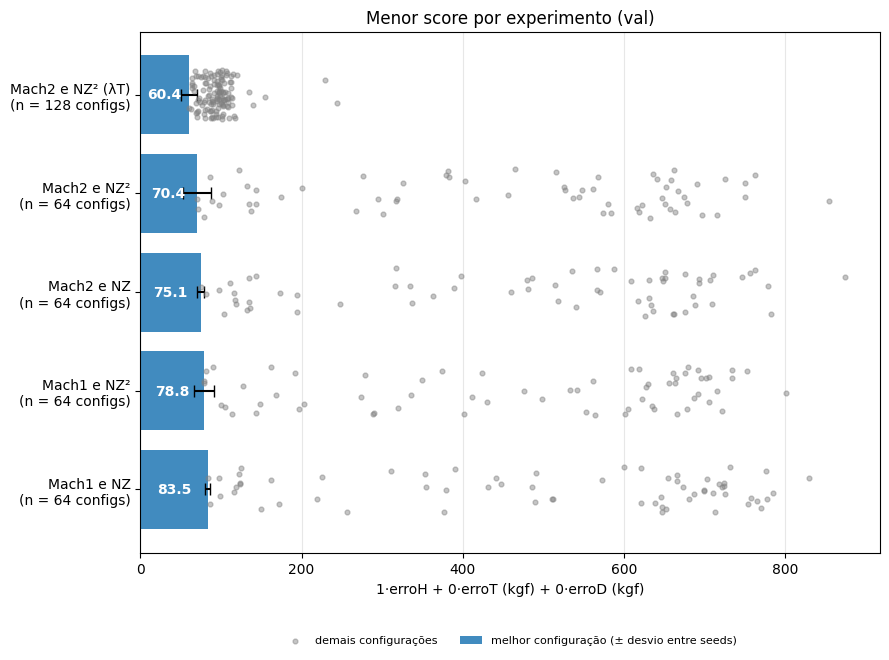

                                          score  desvio_seeds  n_seeds  n_configs  camadas  neuronios  lambda_mono_ng  lambda_mono_t  lambda_anchor  anchor_fraction
pasta                                                                                                                                                               
lhs_anchoring_Mach2_NZsqr_lambdaT       60.4043        9.5170        3        128        5        100             0.0        73.7411       872.1526           0.0491
lhs_anchoring_27092026_Mach2_NZsqr_LHS  70.3619       17.0875        3         64        9         20             0.0         0.0000         0.0443           0.0740
lhs_anchoring_27092026_Mach2_NZ_LHS     75.1244        4.3080        3         64        9         20             0.0         0.0000         0.0443           0.0740
lhs_anchoring_27092026_Mach1_NZsqr_LHS  78.8086       12.1420        3         64        4        100             0.0         0.0000         0.0117           0.0722
lhs_anchor

In [ ]:
# ---------------- Configuração ----------------
CSV_METRICAS   = 'Grid_Searches/metricas_val_todos_modelos.csv'   # saída da célula de avaliação
CONJUNTO       = 'val'
PESO_H, PESO_T, PESO_D = 1, 0, 0        # score = PESO_H*erroH + PESO_T*erroT + PESO_D*erroD
ROTULOS = {
    # 'lhs_anchoring_Mach2_NZsqr_lambdaT': 'Mach² e NZ²',    # opcional: rótulo legível por pasta
    "lhs_anchoring_27092026_Mach1_NZ_LHS": "Mach1 e NZ",
    "lhs_anchoring_27092026_Mach1_NZsqr_LHS": "Mach1 e NZ²",
    "lhs_anchoring_27092026_Mach2_NZ_LHS": "Mach2 e NZ",
    "lhs_anchoring_27092026_Mach2_NZsqr_LHS": "Mach2 e NZ²",
    "lhs_anchoring_Mach2_NZsqr_lambdaT": "Mach2 e NZ² (λT)",
}

CHAVE_HP = ['camadas', 'neuronios', 'lambda_mono_ng', 'lambda_mono_t', 'lambda_anchor', 'anchor_fraction']

# ---------------- Dados ----------------
df = pd.read_csv(CSV_METRICAS)
df = df[df['conjunto'] == CONJUNTO].dropna(subset=['erroH', 'erroT', 'erroD']).copy()
df['score'] = PESO_H * df['erroH'] + PESO_T * df['erroT'] + PESO_D * df['erroD']

# 1) por seed (média sobre voos)  ->  2) por configuração (média e desvio entre seeds)
por_seed = df.groupby(['pasta'] + CHAVE_HP + ['seed'], dropna=False)['score'].mean().reset_index()
cfg = (por_seed.groupby(['pasta'] + CHAVE_HP, dropna=False)['score']
       .agg(score='mean', desvio_seeds='std', n_seeds='count')
       .reset_index())

# melhor (menor score) configuração de cada pasta
melhores = cfg.loc[cfg.groupby('pasta')['score'].idxmin()].set_index('pasta')
melhores['n_configs'] = cfg.groupby('pasta').size()
melhores = melhores.sort_values('score')

# ---------------- Gráfico ----------------
def _quebrar(nome, largura=28):
    """Quebra nomes longos depois dos '_' (sem cortar palavras no meio)."""
    return textwrap.fill(nome.replace('_', '_ '), largura).replace('_ ', '_')

rotulos = [_quebrar(ROTULOS.get(p, p)) + f'\n(n = {int(melhores.loc[p, "n_configs"])} configs)'
           for p in melhores.index]
y = np.arange(len(melhores))

fig, ax = plt.subplots(figsize=(9, 0.9 * len(melhores) + 2.2))
ax.barh(y, melhores['score'], xerr=melhores['desvio_seeds'].fillna(0), color='tab:blue', alpha=0.85,
        capsize=4, zorder=2, label='melhor configuração (± desvio entre seeds)')

rng = np.random.RandomState(0)
for yi, p in zip(y, melhores.index):
    s = cfg.loc[cfg['pasta'] == p, 'score'].to_numpy()
    ax.scatter(s, yi + rng.uniform(-0.25, 0.25, len(s)), s=12, color='gray', alpha=0.45, zorder=3,
               label='demais configurações' if yi == 0 else None)

for yi, v in zip(y, melhores['score']):
    ax.text(v / 2, yi, f'{v:.3g}', ha='center', va='center', color='white', fontweight='bold', zorder=4)

ax.set_yticks(y)
ax.set_yticklabels(rotulos)
ax.invert_yaxis()                      # melhor no topo
ax.set_xlabel(f'{PESO_H}·erroH + {PESO_T}·erroT (kgf) + {PESO_D}·erroD (kgf)')
ax.set_title(f'Menor score por experimento ({CONJUNTO})')
ax.grid(axis='x', alpha=0.3, zorder=0)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8, frameon=False)
fig.tight_layout()

pasta_saida = os.path.dirname(CSV_METRICAS)
fig.savefig(os.path.join(pasta_saida, f'menor_score_por_pasta_{CONJUNTO}.png'), dpi=150, bbox_inches='tight')
plt.show()

# ---------------- Tabela com a melhor configuração de cada pasta ----------------
colunas = ['score', 'desvio_seeds', 'n_seeds', 'n_configs'] + CHAVE_HP
print(melhores[colunas].round(4).to_string())
melhores[colunas].to_csv(os.path.join(pasta_saida, f'melhor_por_pasta_{CONJUNTO}.csv'))

[1, 2, 3, 4]
64
64


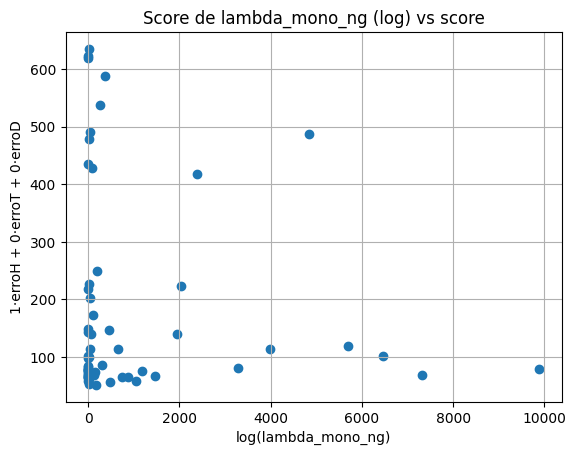

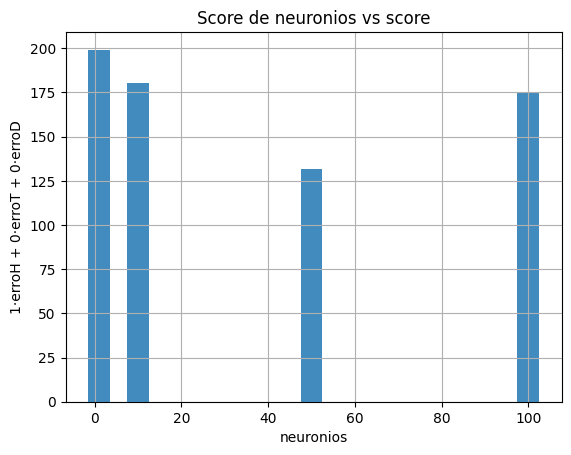

In [35]:
# ---------------- Configuração ----------------
CSV_METRICAS   = 'Grid_Searches/metricas_val_lhs_anchoring_Mach2_NZsqr_lambdaNG.csv'   # saída da célula de avaliação
CONJUNTO       = 'val'
# PESO_H, PESO_T, PESO_D = 0.33, 0.34, 0.33        # score = PESO_H*erroH + PESO_T*erroT + PESO_D*erroD
PESO_H, PESO_T, PESO_D = 1, 0, 0        # score = PESO_H*erroH + PESO_T*erroT + PESO_D*erroD
ROTULOS = {
    # 'lhs_anchoring_Mach2_NZsqr_lambdaT': 'Mach² e NZ²',    # opcional: rótulo legível por pasta
    # "lhs_anchoring_27092026_Mach1_NZ_LHS": "Mach1 e NZ",
    # "lhs_anchoring_27092026_Mach1_NZsqr_LHS": "Mach1 e NZ²",
    # "lhs_anchoring_27092026_Mach2_NZ_LHS": "Mach2 e NZ",
    # "lhs_anchoring_27092026_Mach2_NZsqr_LHS": "Mach2 e NZ²",
    # "lhs_anchoring_Mach2_NZsqr_lambdaT": "Mach2 e NZ² (λT)",
}

CHAVE_HP = ['camadas', 'neuronios', 'lambda_mono_ng', 'lambda_mono_t', 'lambda_anchor', 'anchor_fraction']

# ---------------- Dados ----------------
df = pd.read_csv(CSV_METRICAS)
df = df[df['conjunto'] == CONJUNTO].dropna(subset=['erroH', 'erroT', 'erroD']).copy()
df['score'] = PESO_H * df['erroH'] + PESO_T * df['erroT'] + PESO_D * df['erroD']

list1 = [1,1,2,2,3,4]
list2 = list(dict.fromkeys(list1))
print(list2)

LAMBDA_MONO_NG_OPTS = list(dict.fromkeys(df['lambda_mono_ng']))
print(len(np.log(LAMBDA_MONO_NG_OPTS)))
SCORES_LAMBDA_MONO_NG = []
for lambdas in LAMBDA_MONO_NG_OPTS:
    SCORES_LAMBDA_MONO_NG.append(df[df['lambda_mono_ng'] == lambdas]['score'].mean())
print(len(SCORES_LAMBDA_MONO_NG))
plt.title('Score de lambda_mono_ng (log) vs score')
# plt.bar(np.log(LAMBDA_MONO_NG_OPTS), SCORES_LAMBDA_MONO_NG, width = 0.05)
# plt.scatter(np.log10(LAMBDA_MONO_NG_OPTS), SCORES_LAMBDA_MONO_NG)
plt.scatter(LAMBDA_MONO_NG_OPTS, SCORES_LAMBDA_MONO_NG)
plt.xlabel('log(lambda_mono_ng)'); plt.ylabel(f'{PESO_H}·erroH + {PESO_T}·erroT + {PESO_D}·erroD')
plt.grid(True)
plt.show()

NEURONIOS_OPTS = [1, 10, 50, 100]
SCORES_NEURONIOS = []
for neuronios in NEURONIOS_OPTS:
    SCORES_NEURONIOS.append(df[df['neuronios_z1'] == neuronios]['score'].mean())
plt.title('Score de neuronios vs score')
plt.bar(NEURONIOS_OPTS, SCORES_NEURONIOS, width=5, color='tab:blue', alpha=0.85)
plt.xlabel('neuronios'); plt.ylabel(f'{PESO_H}·erroH + {PESO_T}·erroT + {PESO_D}·erroD')
plt.grid(True)
plt.show()

# CAMADAS_OPTS = [1,2,3,4,5,6,7,8,9,10]
# SCORES_CAMADAS = []
# for camadas in CAMADAS_OPTS:
#     SCORES_CAMADAS.append(df[df['camadas'] == camadas][df['pasta'] == 'lhs_anchoring_Mach2_NZsqr_lambdaT']['score'].mean())
# plt.title('Score de CAMADAS vs score')
# plt.bar(CAMADAS_OPTS, SCORES_CAMADAS)
# plt.xlabel('CAMADAS'); plt.ylabel(f'{PESO_H}·erroH + {PESO_T}·erroT + {PESO_D}·erroD')
# plt.grid(True)
# plt.show()


In [23]:
def teste_rapido(
        neuronio = 10,
        camada = 5,
        lambda_mono = 0.0,
        lambda_anchor = 0,
        anchor_fraction = 0,
        anchor_points = [(0.5, 100.0)],        # ex.: [(0.5, 100.0)]
        anchor_tol_mach = 0.01,
        anchor_tol_n1 = 1.0,
        batch_size = 128,
        epochs = 200,
        patience = 10
):
    hp_teste = {
        'optimizer': 'adam',
        'learning_rate': 0.0001,
        'epochs': epochs,
        'batch_size': batch_size,
        'patience': patience,
        'lambda_mono': lambda_mono,
        'lambda_anchor': lambda_anchor,
        'anchor_fraction': anchor_fraction,
        'anchor_points': anchor_points,
        'anchor_tol_mach': anchor_tol_mach,
        'anchor_tol_n1': anchor_tol_n1,
    }
    df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
        tipo_dados='',
        features1=['Mach', 'N1_over_sqrt_theta'],
        features2=['Mach2', 'NZ_W_dlt_sqr'],
        targets=['Hdot_W_V_dlt'],
        mode='train',
        architecture={
            'neurons': neuronio,
            'camadas_ocultas': camada,
            'activation': 'relu',
            'dropout': 0,
        },
        hyperparameters=hp_teste,
        seed=0
    )

    extractor = keras.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer('NN1_output').output,  # Z1
            model.get_layer('NN2_output').output,  # Z2
            model.output                           # Y (Z1 - Z2)
        ]
    )

    features1 = ['Mach', 'N1_over_sqrt_theta']
    features2 = ['Mach2', 'NZ_W_dlt_sqr']

    features1_scaled = [f + '_scaled' for f in features1]
    features2_scaled = [f + '_scaled' for f in features2]

    X1_all = np.array(df[features1_scaled]).astype(np.float32)
    X2_all = np.array(df[features2_scaled]).astype(np.float32)

    z1_vals, z2_vals, y_vals = extractor.predict([X1_all, X2_all])

    # Adiciona ao DataFrame (ainda em escala normalizada)
    df['Z1_scaled'] = z1_vals.flatten()
    df['Z2_scaled'] = z2_vals.flatten()

    df['Z1_minus_Z2'] = scaler_y.inverse_transform(y_vals).flatten()
    df['Z1'] = scaler_y.inverse_transform(z1_vals).flatten()
    df['Z2'] = df['Z1'] - df['Z1_minus_Z2']

    df['Tn_dlt'] = (df['T'] * np.cos(np.radians(df['Alfa'])) / df['delta']) * 0.453592
    df['D_dlt'] = df['Tn_dlt'] - df['Hdot_W_V_dlt']

    c_offset, std_res_anc, n_anc = calcular_offset_ancoras(df, hp_teste)
    df['Z1'] += c_offset
    df['Z2'] += c_offset
    print(f"Offset das âncoras: c = {c_offset:.1f} kgf | desvio do resíduo = {std_res_anc:.1f} kgf | n = {n_anc}")

    evaluated_set = 'test'

    subset = df[df['type'] == evaluated_set]

    voos_presentes = [f for f in subset['filename'].unique() if f in time_intervals]

    metricas = []

    for col_idx, filename in enumerate(voos_presentes):
        grupo = subset[subset['filename'] == filename]
        t0, t = time_intervals[filename]
        mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
        grupo = grupo[mask].copy()

        erroH = abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']).mean()
        erroD = abs(grupo['D_dlt'] - grupo['Z2']).mean()
        erroT = abs(grupo['Tn_dlt'] - grupo['Z1']).mean()

        metricas.append({
            'camadas': camada, 'neuronios': neuronio, 'lambda_mono': lambda_mono, 'lambda_anchor': lambda_anchor, 'anchor_fraction': anchor_fraction,
            'filename': filename,
            'erroH': erroH, 'erroD': erroD, 'erroT': erroT
        })

        # base = os.path.join(combo_dir, filename)

        # # --- linha 0: pred vs real ---
        # plt.figure(figsize=(10, 4))
        # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
        # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'], s=dot_size, label='Hdot_W_V_dlt')
        # plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
        # plt.plot()

        # # --- linha 1: erro absoluto ---
        # plt.figure(figsize=(10, 4))
        # plt.scatter(grupo['TEMPO_SAD'], abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']), s=dot_size,
        #             label='|Hdot_W_V_dlt_pred - Hdot_W_V_dlt|')
        # plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
        # plt.plot()

        # plt.figure(figsize=(10, 4))
        # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
        # plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'] - grupo['Z2'], s=dot_size, label='Z1 - Z2')
        # plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
        # plt.plot()

        # --- linha 2: Z1 vs Tn_dlt ---
        plt.figure(figsize=(10, 4))
        plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'], s=dot_size, label='Z1')
        plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
        plt.legend(markerscale=5); plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
        plt.xlabel('DAQ Time (s)'); plt.grid()
        plt.plot()

        # --- linha 3: Z2 vs D_dlt ---
        plt.figure(figsize=(10, 4))
        plt.scatter(grupo['TEMPO_SAD'], grupo['Z2'], s=dot_size, label='Z2')
        plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label=r'D/$\delta$')
        plt.legend(markerscale=5); plt.ylabel(r'Z2 and D/$\delta$ (kgf)')
        plt.xlabel('DAQ Time (s)'); plt.grid()
        plt.plot()

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Âncoras (treino): 224 pontos (0.80%)
Treinando modelo...
1074/1074 ━━━━━━━━━━━━━━━━━━━━ 1s 666us/step
1074/1074 ━━━━━━━━━━━━━━━━━━━━ 1s 661us/step
Offset das âncoras: c = -235.3 kgf | desvio do resíduo = 33.0 kgf | n = 224


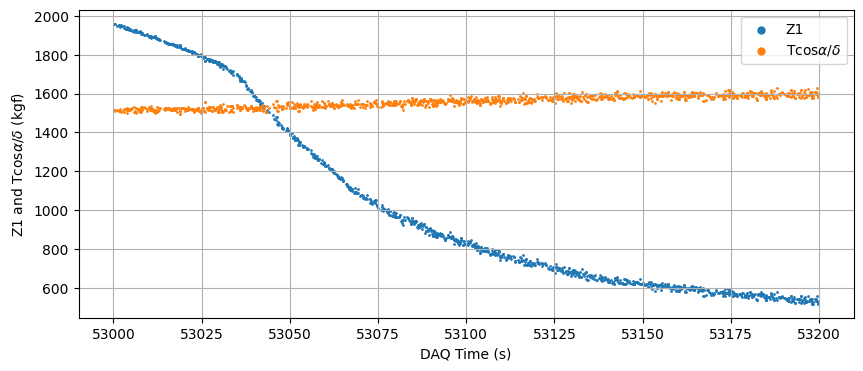

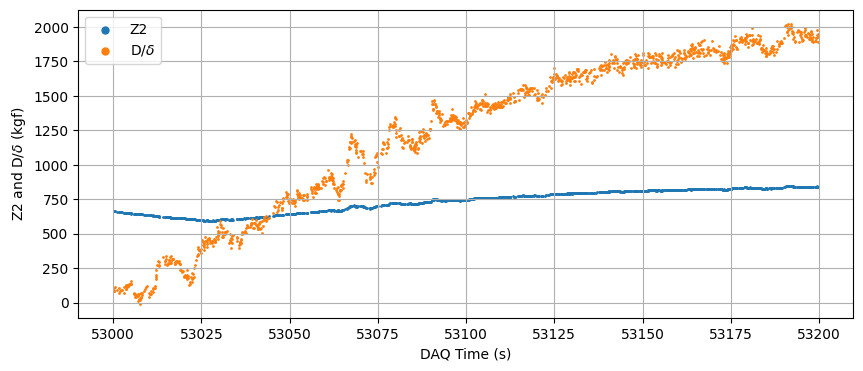

In [26]:
neuronio = 10
camada = 4
lambda_mono = 0.0
lambda_anchor = 0.00
anchor_fraction = 0.00
teste_rapido(neuronio, camada, lambda_mono, lambda_anchor, anchor_fraction)

[]

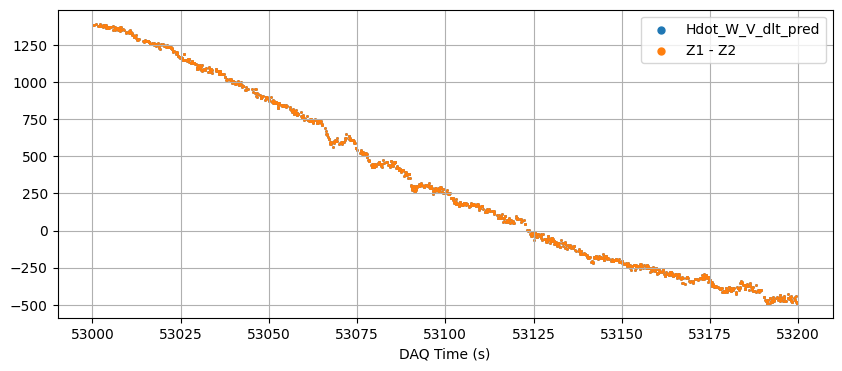

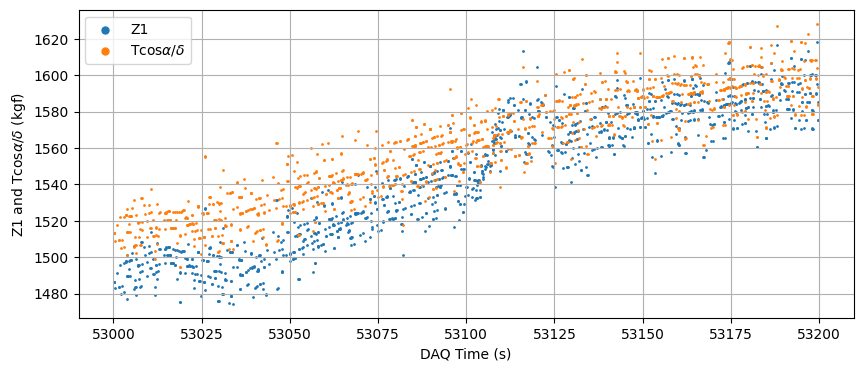

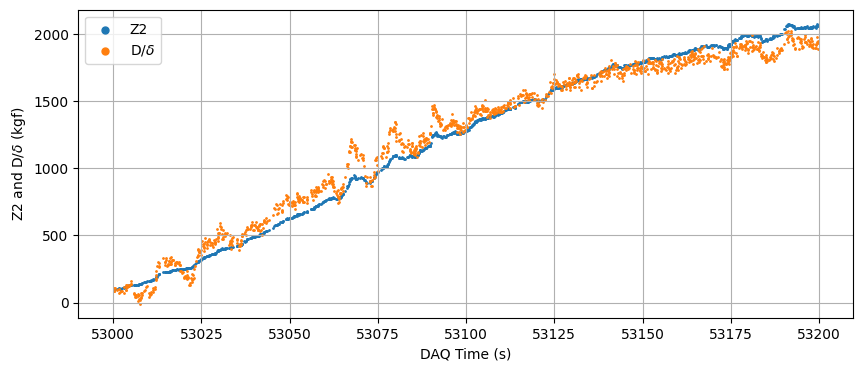

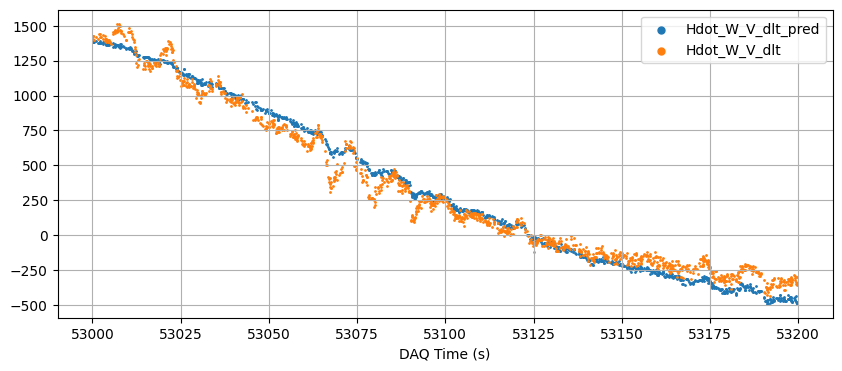

In [59]:
# k = min(min(grupo['Z1']), min(grupo['Z2']))
# grupo['Z1'], grupo['Z2'] = (
#     grupo['Z1'] - k + (grupo['Hdot_W_V_dlt_pred'] - (grupo['Z1'] - grupo['Z2'])).mean(),
#     grupo['Z2'] - k
# )
plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'] + (grupo['Hdot_W_V_dlt'] - grupo['Hdot_W_V_dlt_pred']).mean(), s=dot_size, label='Hdot_W_V_dlt_pred')
plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'] - grupo['Z2'] + (grupo['Hdot_W_V_dlt'] - grupo['Hdot_W_V_dlt_pred']).mean(), s=dot_size, label='Z1 - Z2')
plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()

# --- linha 2: Z1 vs Tn_dlt ---
plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Z1']+ (grupo['Hdot_W_V_dlt'] - grupo['Hdot_W_V_dlt_pred']).mean() + 100, s=dot_size, label='Z1')
plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
plt.legend(markerscale=5); plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()


# --- linha 3: Z2 vs D_dlt ---
plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Z2'] + + 100, s=dot_size, label='Z2')
plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label=r'D/$\delta$')
plt.legend(markerscale=5); plt.ylabel(r'Z2 and D/$\delta$ (kgf)')
plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()

plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'] + (grupo['Hdot_W_V_dlt'] - grupo['Hdot_W_V_dlt_pred']).mean(), s=dot_size, label='Hdot_W_V_dlt_pred')
dy = 0
plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'] + dy, s=dot_size, label='Hdot_W_V_dlt')
# plt.scatter(grupo['TEMPO_SAD'], (grupo['Tn_dlt'] - grupo['D_dlt']), s=dot_size, label=r'Tcos$\alpha$/$\delta$ - D/$\delta$')
plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()
